# TA05 — Experimentos com o MLP *from scratch*

**CI1026 — Visão Computacional e Percepção** · UFPR · 2º semestre de 2026 · Prof. Eduardo Todt

**Dupla:** Débora Zanoello · *[nome do(a) colega]*

Este notebook parte do notebook *MLP from scratch* fornecido na disciplina (adaptado de Vítor Gama Lemos) e está organizado em quatro partes:

1. **Notebook original**, preservado sem alterações e reexecutado.
2. **Depuração**: cada bug encontrado é demonstrado com código.
3. **Implementação corrigida** da MLP, verificada com *gradient check*.
4. **Experimentos**: efeito das correções, convergência (normalização, taxa de aprendizado, ativação, função de custo), capacidade (neurônios ocultos), *overfitting*, avaliação final com validação cruzada, análise de erros e fronteiras de decisão.

As figuras usadas no artigo são salvas na pasta `figuras/` e os números principais em `resultados.json`.

---
## Parte 1 — Notebook original (sem alterações)

As células abaixo são exatamente as do notebook fornecido. Ao final desta parte, o modelo acerta 29 de 30 amostras de teste, mas o conjunto de teste tem **20 setosa, 9 versicolor e só 1 virginica**, e essa única virginica é classificada errado. A Parte 2 explica por quê.

MULTI-LAYER PERCEPTRON FROM SCRATCH
Adapted from original notebook from Vítor Gama Lemos

[kaggle-notebook](https://www.kaggle.com/code/vitorgamalemos/multilayer-perceptron-from-scratch)


In [1]:
import random
import seaborn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

seaborn.set(style='whitegrid'); seaborn.set_context('talk')
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

from sklearn.datasets import load_iris
iris_data = load_iris()

In [2]:
print(iris_data['DESCR'])

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

Number of samples: 150
Number of features: 4 



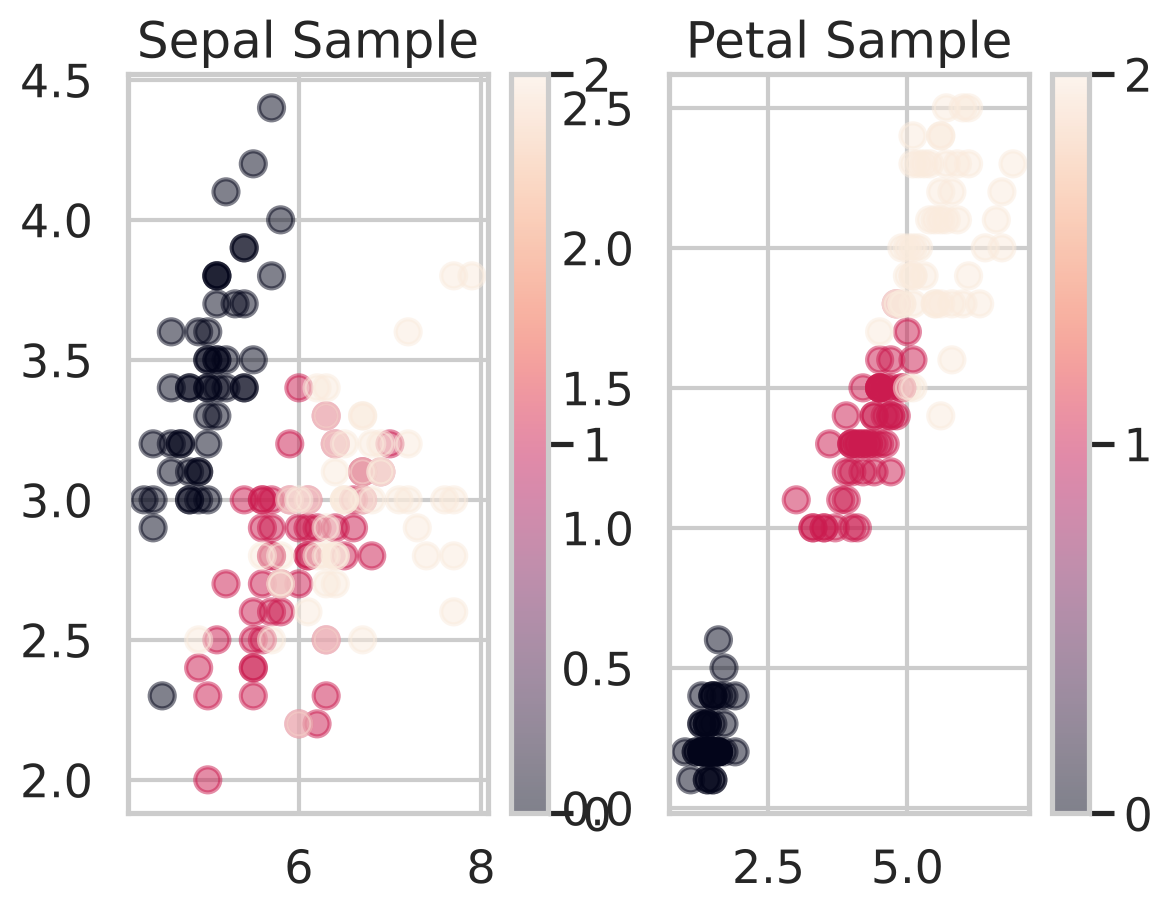

In [3]:
n_samples, n_features = iris_data.data.shape

print(f"Number of samples: {n_samples}")
print(f"Number of features: {n_features} \n")

plt.subplot(1, 2, 1)
scatter_plot = plt.scatter(iris_data.data[:,0], iris_data.data[:,1], alpha=0.5,
                           c=iris_data.target)
plt.colorbar(ticks=([0, 1, 2]))
plt.title('Sepal Sample');

plt.subplot(1, 2, 2)
scatter_plot_2 = plt.scatter(iris_data.data[:,2], iris_data.data[:,3], alpha=0.5,
                           c=iris_data.target)
plt.colorbar(ticks=([0, 1, 2]))
plt.title('Petal Sample');

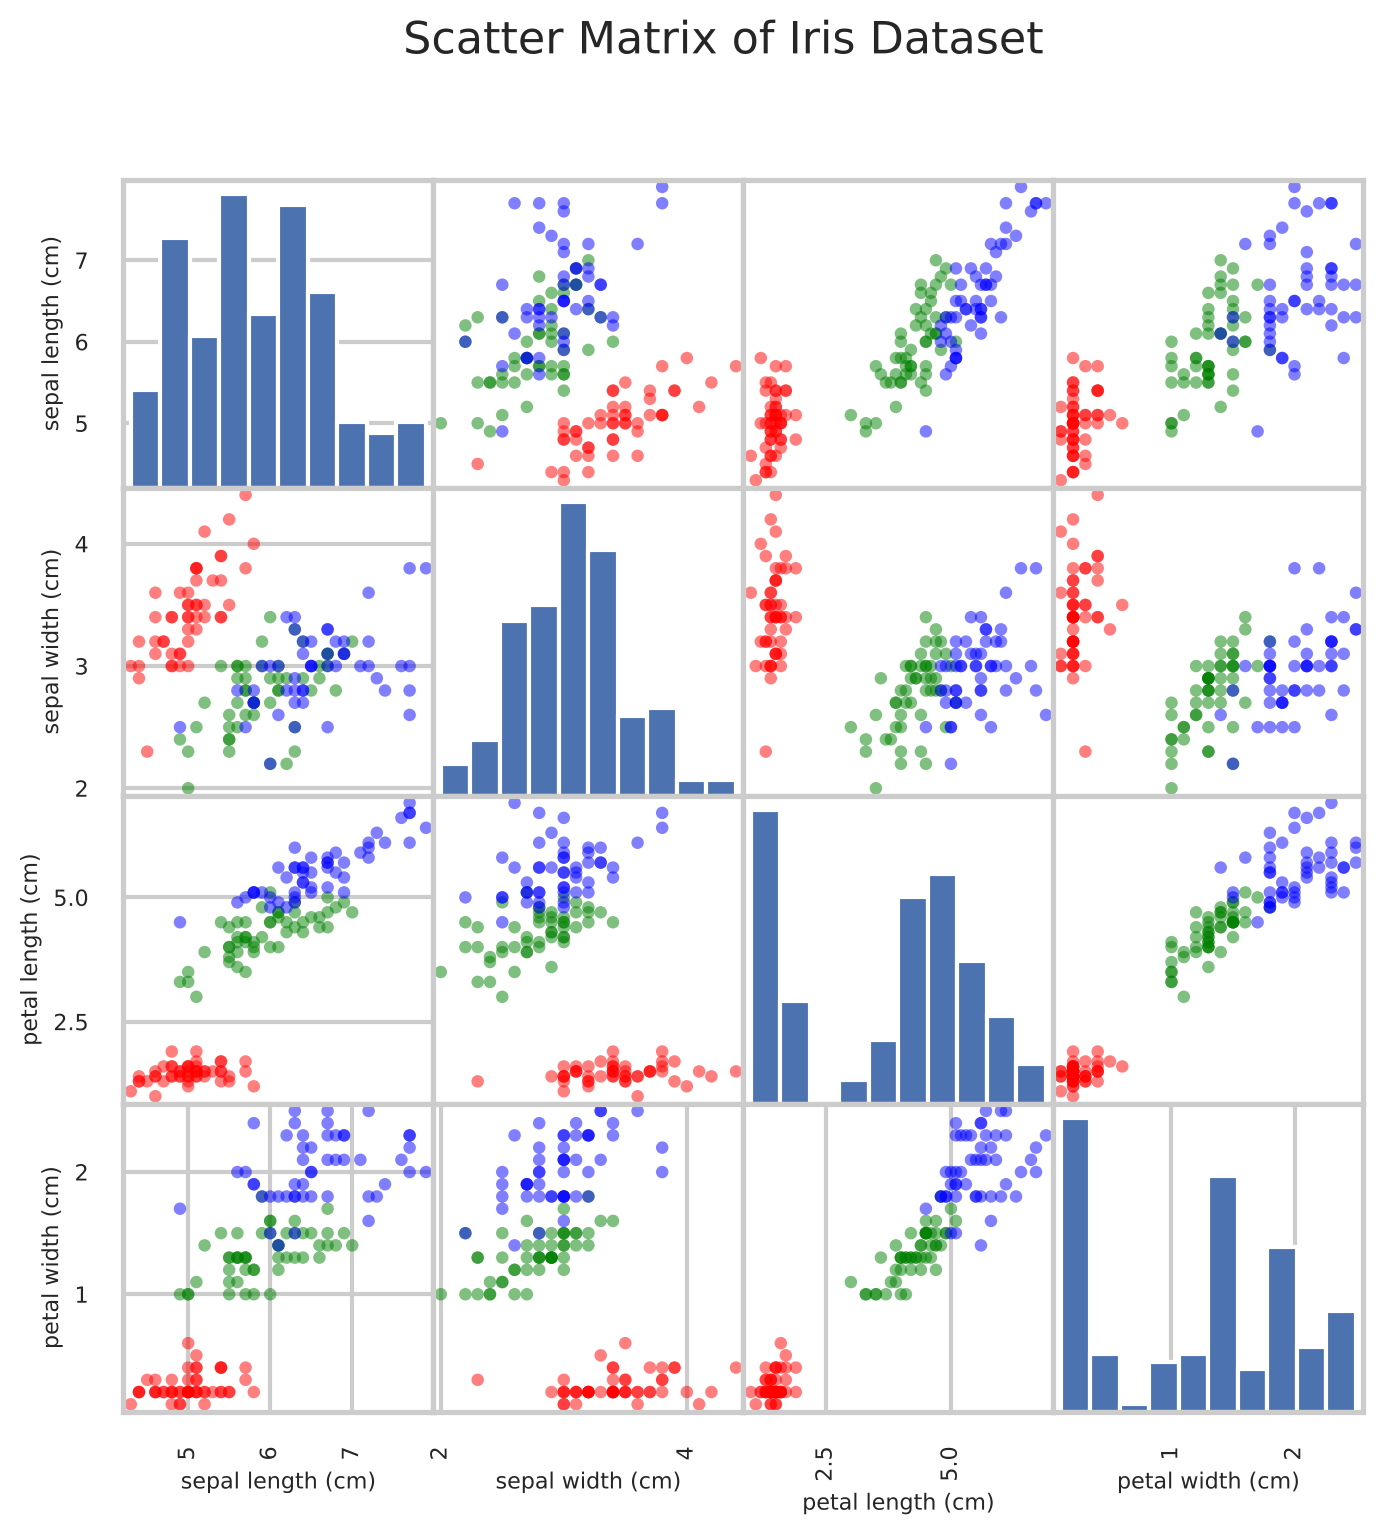

In [4]:
import pandas
from pandas.plotting import scatter_matrix


# Cria um DataFrame com os dados e os nomes das colunas
df = pd.DataFrame(iris_data.data, columns=iris_data.feature_names)
df['target'] = iris_data.target

# Mapeia os números das classes para nomes legíveis
target_names = iris_data.target_names
df['target_name'] = df['target'].apply(lambda i: target_names[i])

# Escolhe uma paleta de cores
colors = {'setosa': 'red', 'versicolor': 'green', 'virginica': 'blue'}
df['color'] = df['target_name'].map(colors)

# Gera o scatter_matrix
axes = scatter_matrix(df[iris_data.feature_names],
               figsize=(8, 8),
               diagonal='hist',
               color=df['color'],
               alpha=0.5)

# Reduz o tamanho da fonte dos rótulos dos eixos
for ax in axes.ravel():
    ax.set_xlabel(ax.get_xlabel(), fontsize=8)
    ax.set_ylabel(ax.get_ylabel(), fontsize=8)

plt.suptitle("Scatter Matrix of Iris Dataset", fontsize=16)
plt.show()

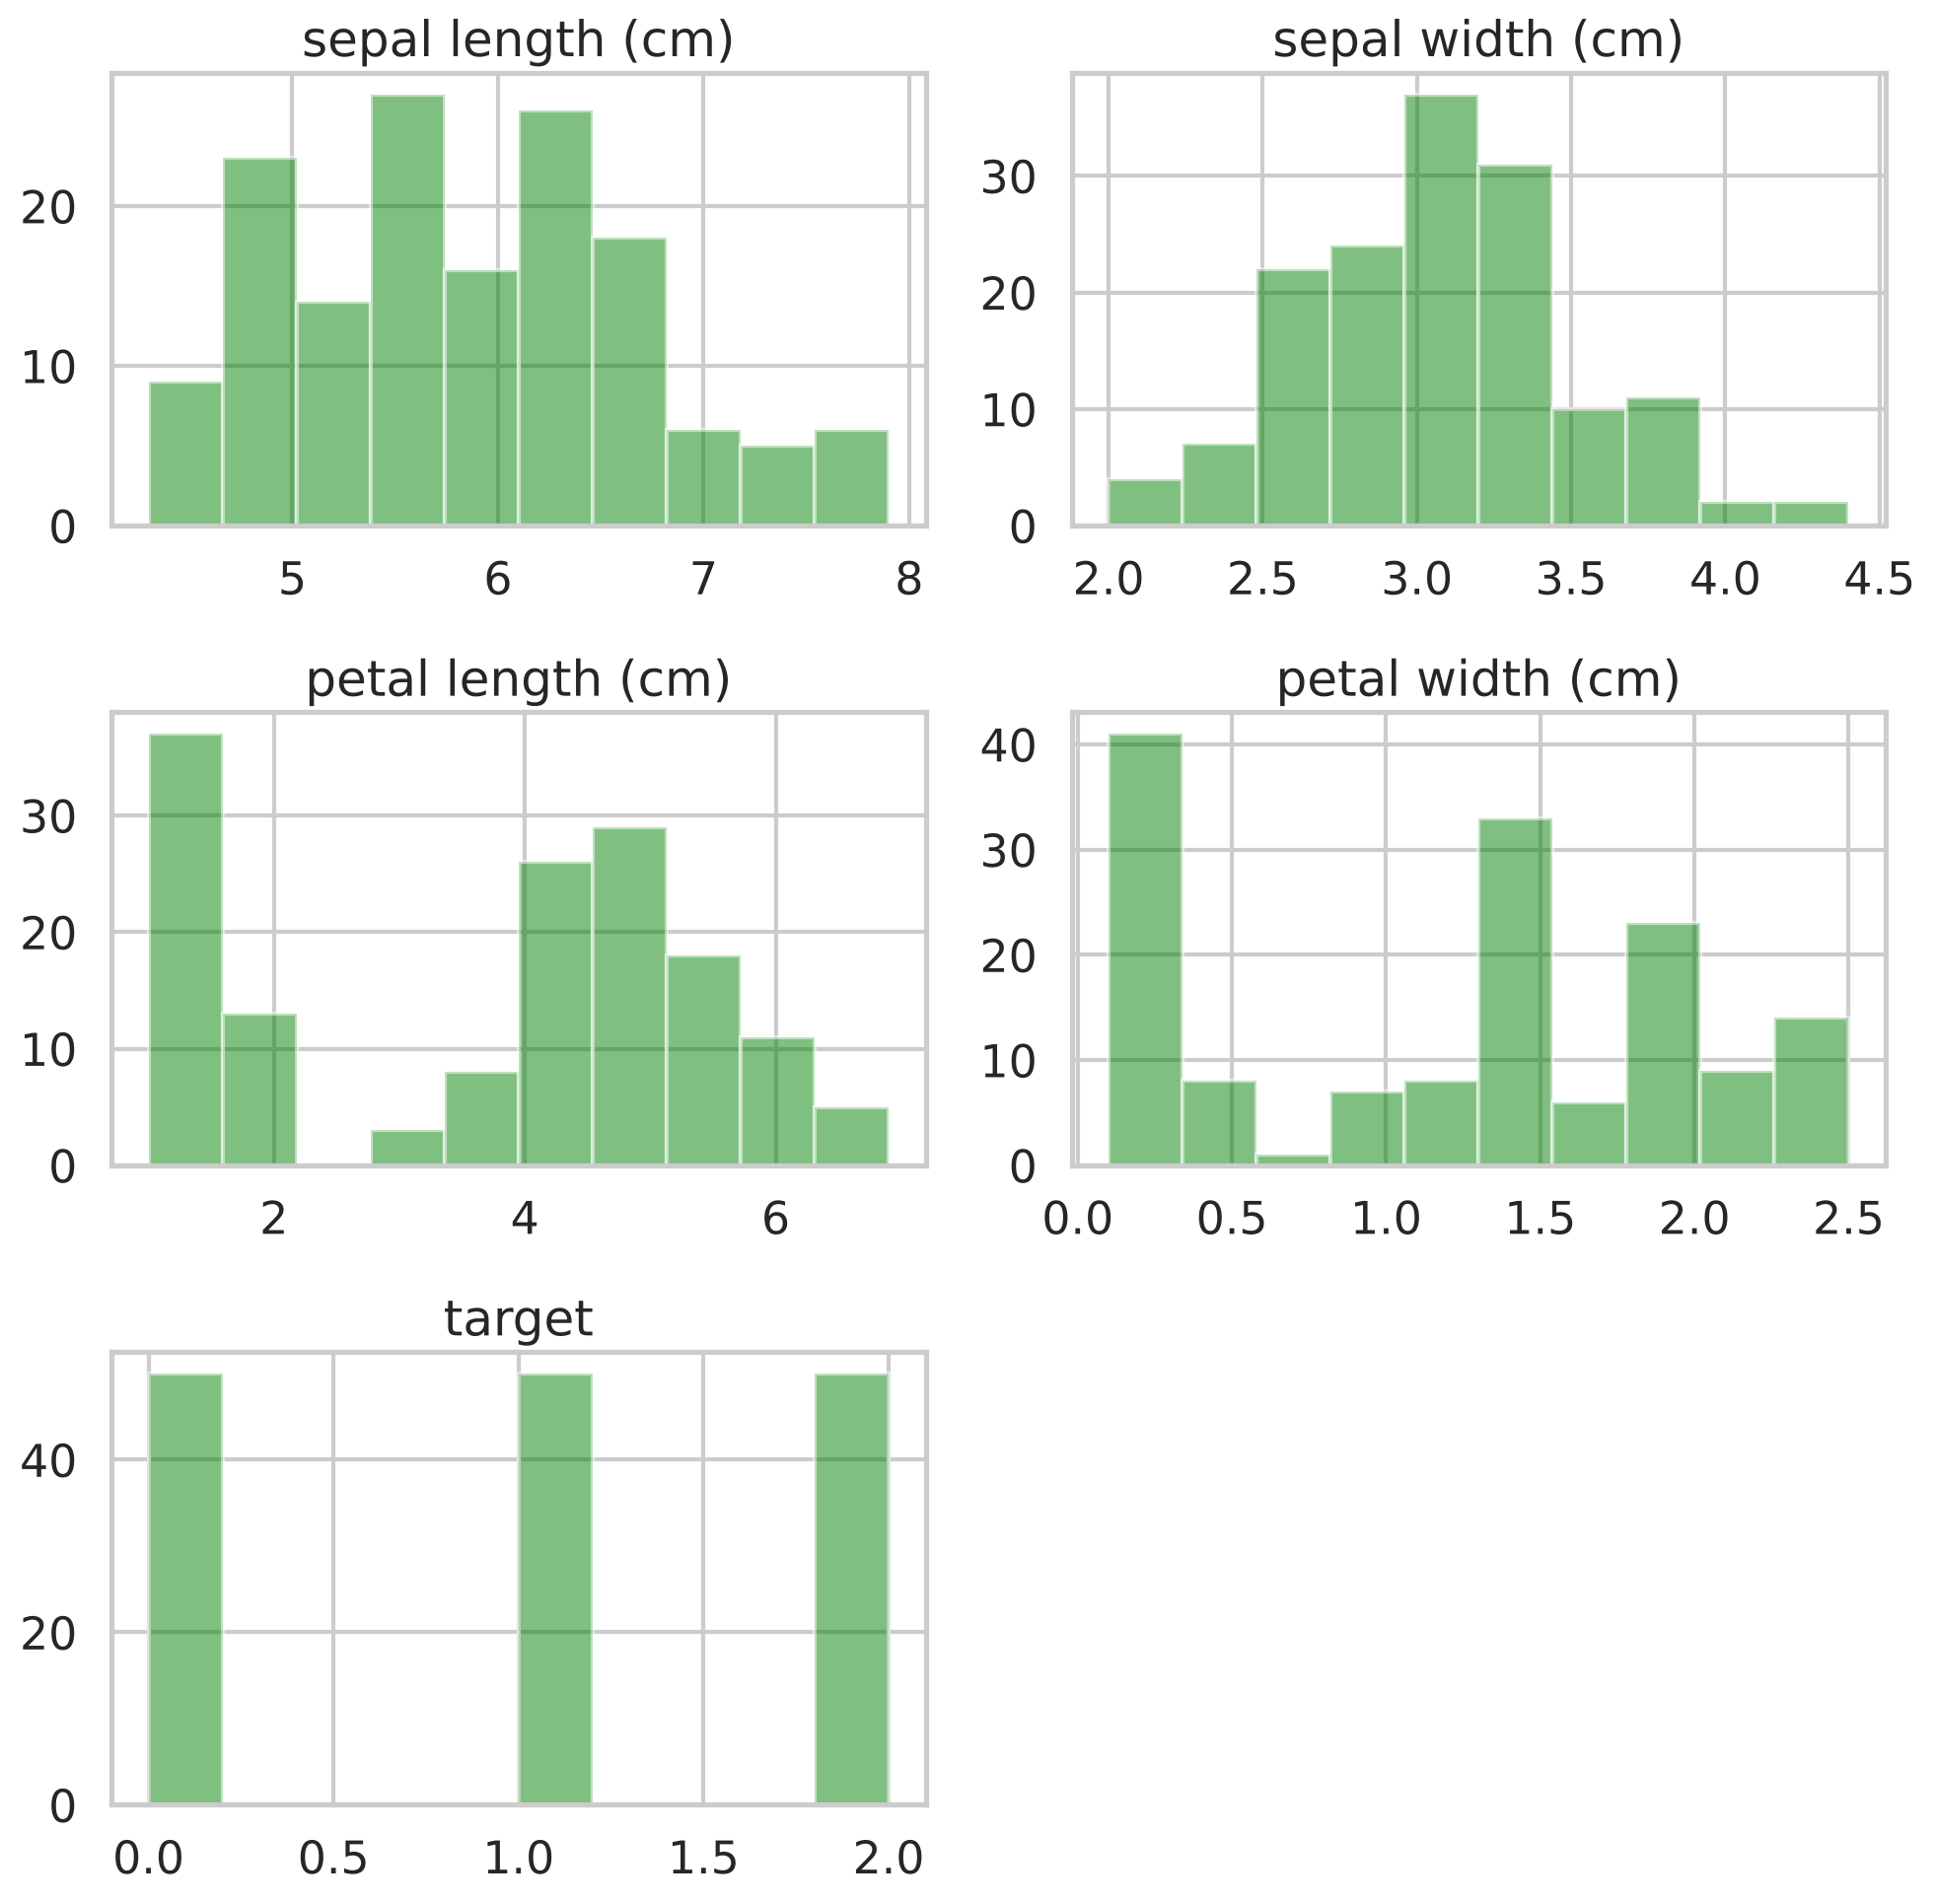

In [5]:
axes = df.hist(alpha=0.5, figsize=(10, 10), color='green')

plt.tight_layout()
plt.show()

In [6]:
import numpy as np
import random
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris

# Load the Iris dataset
iris_data = load_iris()

# Join features and labels into a single array
iris_dataset = np.column_stack((iris_data.data, iris_data.target.T))  # shape (150, 5)

# Shuffle the dataset (optional: for reproducibility)
random.seed(123)
random.shuffle(iris_dataset)

# Split features (X) and labels (y)
X = np.array([i[:4] for i in iris_dataset])  # shape (150, 4)
y = np.array([i[4] for i in iris_dataset])   # shape (150,)

# Use train_test_split to divide into 80% train, 20% test
train_X, test_X, train_y, test_y = train_test_split(
    X, y,
    test_size=0.2,
    random_state=11,  # set for reproducibility
    stratify=y        # keep label proportions balanced
)

# Now you have train_X, train_y, test_X, test_y ready

print(test_y)

[0. 0. 0. 1. 1. 0. 1. 0. 1. 0. 0. 1. 0. 0. 1. 0. 1. 0. 0. 2. 0. 0. 1. 0.
 0. 1. 0. 0. 0. 0.]


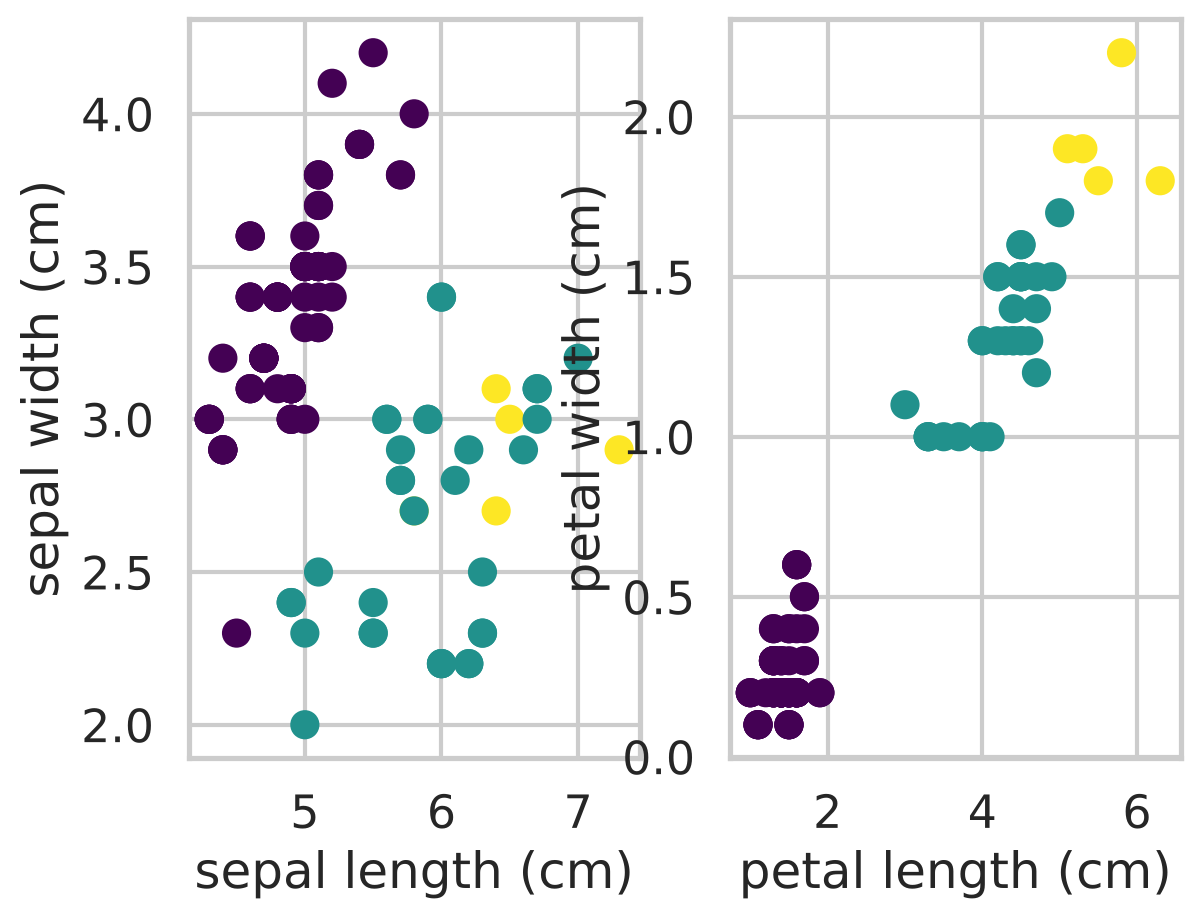

In [7]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Plot training Samples

plt.subplot(1, 2, 1)
plt.scatter(train_X[:,0],train_X[:,1],c=train_y,cmap=cm.viridis)
plt.xlabel(iris_data.feature_names[0])
plt.ylabel(iris_data.feature_names[1])

plt.subplot(1, 2, 2)
plt.scatter(train_X[:,2],train_X[:,3],c=train_y,cmap=cm.viridis)
plt.xlabel(iris_data.feature_names[2])
plt.ylabel(iris_data.feature_names[3]);

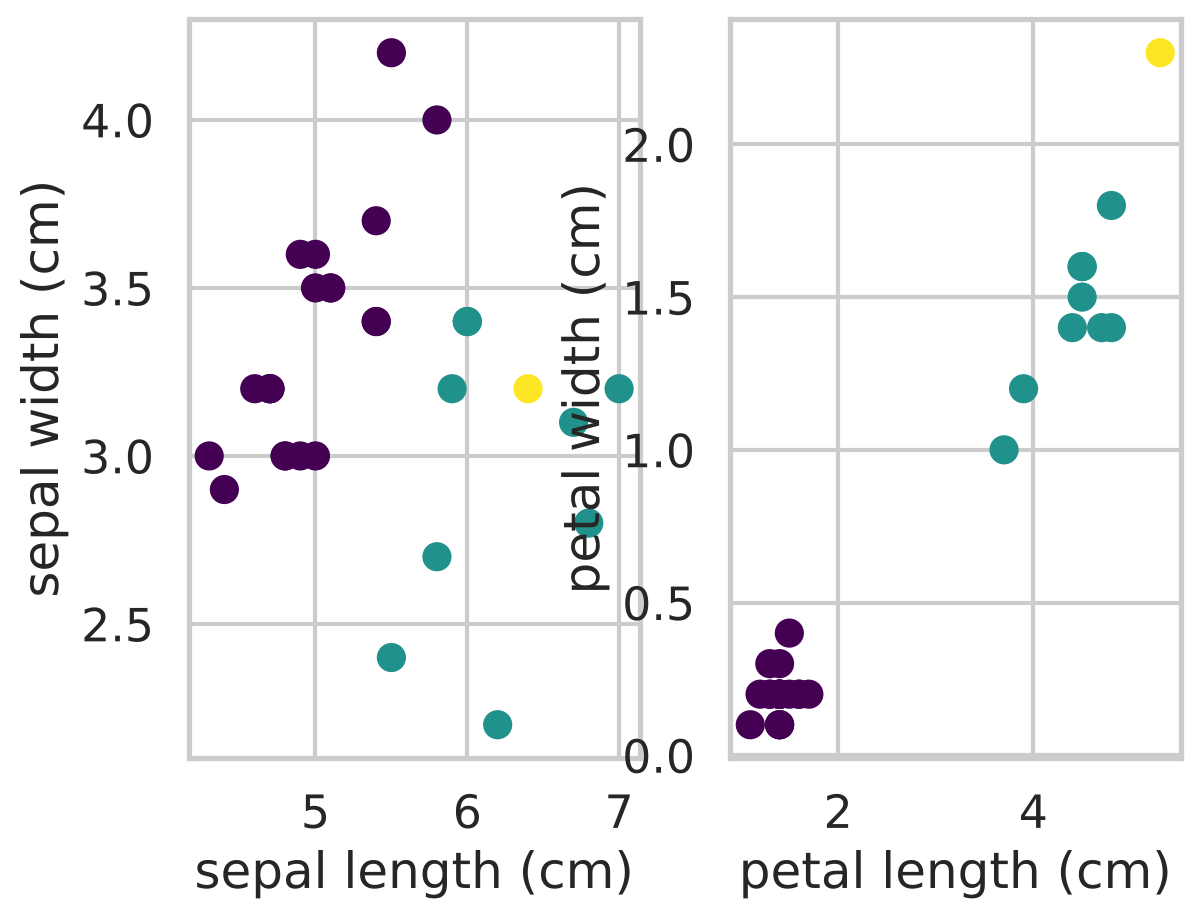

In [8]:
# Plot test samples
plt.subplot(1, 2, 1)
plt.scatter(test_X[:,0],test_X[:,1],c=test_y,cmap=cm.viridis)
plt.xlabel(iris_data.feature_names[0])
plt.ylabel(iris_data.feature_names[1])

plt.subplot(1, 2, 2)
plt.scatter(test_X[:,2],test_X[:,3],c=test_y,cmap=cm.viridis)
plt.xlabel(iris_data.feature_names[2])
plt.ylabel(iris_data.feature_names[3]);

In [9]:
# Implementation the Multilayer Perceptron in Python
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
import random
import numpy as np
import matplotlib.pyplot as plt

class MultiLayerPerceptron(BaseEstimator, ClassifierMixin):

    def __init__(self, params=None):
        # Store the params argument to satisfy BaseEstimator requirements
        self.params = params

        if (params == None):
            self.inputLayer = 4                        # Input Layer
            self.hiddenLayer = 5                       # Hidden Layer
            self.outputLayer = 3                       # Outpuy Layer
            self.learningRate = 0.005                  # Learning rate
            self.max_epochs = 600                      # Epochs
            self.iasHiddenValue = -1                   # Bias HiddenLayer
            self.BiasOutputValue = -1                  # Bias OutputLayer
            self.activation = self.ativacao['sigmoid'] # Activation function
            self.deriv = self.derivada['sigmoid']
        else:
            self.inputLayer = params['InputLayer']
            self.hiddenLayer = params['HiddenLayer']
            self.outputLayer = params['OutputLayer']
            self.learningRate = params['LearningRate']
            self.max_epochs = params['Epocas']
            self.BiasHiddenValue = params['BiasHiddenValue']
            self.BiasOutputValue = params['BiasOutputValue']
            self.activation = self.ativacao[params['ActivationFunction']]
            self.deriv = self.derivada[params['ActivationFunction']]

        # Starting Bias and Weights
        # assign ramdom values [-1 .. +1] in order to start with some weights
        # not so symmetric
        # Weight initialization: passing correct arguments to starting_weights
        self.WEIGHT_hidden = self.starting_weights(self.inputLayer, self.hiddenLayer)
        self.WEIGHT_output = self.starting_weights(self.hiddenLayer, self.outputLayer)

        self.BIAS_hidden = np.array([self.BiasHiddenValue for i in range(self.hiddenLayer)])
        self.BIAS_output = np.array([self.BiasOutputValue for i in range(self.outputLayer)]) # Corrected attribute name
        self.classes_number = 3

    pass

    # This function creates a 2D matrix of random values between -1 and +1
    # Shape: rows x columns
    def starting_weights(self, rows, columns):
        return [[2  * random.random() - 1 for _ in range(columns)] for _ in range(rows)]

    ativacao = {
         'sigmoid': (lambda x: 1/(1 + np.exp(-x))),
            'tanh': (lambda x: np.tanh(x)),
            'Relu': (lambda x: x*(x > 0)),
               }
    derivada = {
         'sigmoid': (lambda x: x*(1-x)),
            'tanh': (lambda x: 1-x**2),
            'Relu': (lambda x: 1 * (x>0))
               }

    # This calculates the error at the output layer and then propagates it
    # backward through the network to update the weights in each layer
    def Backpropagation_Algorithm(self, x):
        DELTA_output = []
        # Stage 1 - Error: OutputLayer (target - predicted)
        ERROR_output = self.output - self.OUTPUT_L2
        DELTA_output = ((-1)*(ERROR_output) * self.deriv(self.OUTPUT_L2))

        arrayStore = []
        # Stage 2 - Update weights OutputLayer and HiddenLayer
        for i in range(self.hiddenLayer):
            for j in range(self.outputLayer): # Corrected attribute name
                self.WEIGHT_output[i][j] -= (self.learningRate * (DELTA_output[j] * self.OUTPUT_L1[i]))
                self.BIAS_output[j] -= (self.learningRate * DELTA_output[j])

        # Stage 3 - Error: HiddenLayer
        delta_hidden = np.matmul(self.WEIGHT_output, DELTA_output)* self.deriv(self.OUTPUT_L1)

        # Stage 4 - Update weights HiddenLayer and InputLayer(x)
        for i in range(self.inputLayer):
            for j in range(self.hiddenLayer):
                self.WEIGHT_hidden[i][j] -= (self.learningRate * (delta_hidden[j] * x[i]))
                self.BIAS_hidden[j] -= (self.learningRate * delta_hidden[j])



    def show_err_graphic(self,v_erro,v_epoca):
        plt.figure(figsize=(9,4))
        plt.plot(v_epoca, v_erro, color="b", marker=11)
        plt.xlabel("Number of Epochs")
        plt.ylabel("Squared error (MSE) ");
        plt.title("Error Minimization")
        plt.show()


    def predict(self, X, y):
        'Returns the predictions for every element of X'
        my_predictions = []
        'Forward Propagation'
        forward = np.matmul(X,self.WEIGHT_hidden) + self.BIAS_hidden
        forward = np.matmul(forward, self.WEIGHT_output) + self.BIAS_output
        for i in forward:
            my_predictions.append(max(enumerate(i), key=lambda x:x[1])[0])

        array_score = []
        for i in range(len(my_predictions)):
            if my_predictions[i] == 0:
                array_score.append([i, 'Iris-setosa', my_predictions[i], y[i]])
            elif my_predictions[i] == 1:
                 array_score.append([i, 'Iris-versicolour', my_predictions[i], y[i]])
            elif my_predictions[i] == 2:
                 array_score.append([i, 'Iris-virginica', my_predictions[i], y[i]])

        dataframe = pd.DataFrame(array_score, columns=['_id', 'class', 'output', 'hoped_output'])
        return my_predictions, dataframe

    def fit(self, X, y):
        count_epoch = 1
        total_error = 0
        n = len(X);
        epoch_array = []
        error_array = []
        # Initialize lists to store specific weight values for plotting
        weight_over_epochs_W0_plot = []
        weight_over_epochs_W1_plot = []


        while(count_epoch <= self.max_epochs):
            for idx,inputs in enumerate(X):
                self.output = np.zeros(self.classes_number)
                'Stage 1 - (Forward Propagation)'
                self.OUTPUT_L1 = self.activation((np.dot(inputs, self.WEIGHT_hidden) + self.BIAS_hidden))
                self.OUTPUT_L2 = self.activation((np.dot(self.OUTPUT_L1, self.WEIGHT_output) + self.BIAS_output))
                'Stage 2 - One-Hot-Encoding'
                if(y[idx] == 0):
                    self.output = np.array([1,0,0]) #Class1 {1,0,0}
                elif(y[idx] == 1):
                    self.output = np.array([0,1,0]) #Class2 {0,1,0}
                elif(y[idx] == 2):
                    self.output = np.array([0,0,1]) #Class3 {0,0,1}

                square_error = 0
                for i in range(self.outputLayer):
                    erro = (self.output[i] - self.OUTPUT_L2[i])**2
                    square_error = (square_error + (0.05 * erro))
                    total_error = total_error + square_error

                'Backpropagation : Update Weights'
                self.Backpropagation_Algorithm(inputs)

            # The original code calculates total_error per batch, then divides by n (number of samples).
            # It's more standard to calculate the mean squared error per epoch by summing errors over
            # all samples in the epoch and then dividing by the number of output neurons.
            # Keeping the original logic for total_error calculation, but this is not
            # a standard MSE calculation.
            total_error = (total_error / n)
            if((count_epoch % 50 == 0)or(count_epoch == 1)):
                print("Epoch ", count_epoch, "- Total Error: ",total_error)
                error_array.append(total_error)
                epoch_array.append(count_epoch)
                # Append the specific weight values only when we are recording the epoch
                weight_over_epochs_W0_plot.append(self.WEIGHT_hidden[0][0])
                weight_over_epochs_W1_plot.append(self.WEIGHT_output[0][0])


            # Reset total_error for the next epoch
            total_error = 0

            count_epoch += 1
        self.show_err_graphic(error_array,epoch_array)

        # Plot the change of a *single* weight over the epochs that were recorded
        plt.figure(figsize=(8, 4))
        # Use the new lists which have the same length as epoch_array
        plt.plot(epoch_array, weight_over_epochs_W0_plot, label='Weight[0][0]')
        plt.title('Change of a Sample Weight (Input 0 to Hidden 0) over Epochs')
        plt.xlabel('Number of Epochs')
        plt.ylabel('Weight Value')
        plt.legend()
        plt.show()

        plt.figure(figsize=(8, 4))
        # Use the new lists which have the same length as epoch_array
        plt.plot(epoch_array, weight_over_epochs_W1_plot, label='Weight[0][0]')
        plt.title('Change of a Sample Weight (Hidden 0 to Output 0) over Epochs')
        plt.xlabel('Number of Epochs')
        plt.ylabel('Weight Value')
        plt.legend()
        plt.show()


        return self

Epoch  1 - Total Error:  0.06758981166881102


Epoch  50 - Total Error:  0.04024720417130557


Epoch  100 - Total Error:  0.02286486557652496


Epoch  150 - Total Error:  0.013276352862066253


Epoch  200 - Total Error:  0.009687618408255076


Epoch  250 - Total Error:  0.008328459058811613


Epoch  300 - Total Error:  0.0076146884903298484


Epoch  350 - Total Error:  0.007178426628736327


Epoch  400 - Total Error:  0.006884936325329666


Epoch  450 - Total Error:  0.006674112495662895


Epoch  500 - Total Error:  0.0065154558916519925


Epoch  550 - Total Error:  0.006391971206018786


Epoch  600 - Total Error:  0.006293445523627044


Epoch  650 - Total Error:  0.006213323972163787


Epoch  700 - Total Error:  0.0061471506262275695


Epoch  750 - Total Error:  0.006091753825413656


Epoch  800 - Total Error:  0.006044802234347228


Epoch  850 - Total Error:  0.006004547869273663


Epoch  900 - Total Error:  0.0059696645270964875


Epoch  950 - Total Error:  0.0059391375688427886


Epoch  1000 - Total Error:  0.005912184529414888


Epoch  1050 - Total Error:  0.005888196576663132


Epoch  1100 - Total Error:  0.005866695164380848


Epoch  1150 - Total Error:  0.005847300024901325


Epoch  1200 - Total Error:  0.00582970559317069


Epoch  1250 - Total Error:  0.005813663628426168


Epoch  1300 - Total Error:  0.005798970348017752


Epoch  1350 - Total Error:  0.0057854568313516356


Epoch  1400 - Total Error:  0.005772981795247586


Epoch  1450 - Total Error:  0.00576142609722956


Epoch  1500 - Total Error:  0.005750688507640086


Epoch  1550 - Total Error:  0.005740682422388199


Epoch  1600 - Total Error:  0.0057313332803714525


Epoch  1650 - Total Error:  0.005722576514513584


Epoch  1700 - Total Error:  0.005714355911196575


Epoch  1750 - Total Error:  0.005706622285460165


Epoch  1800 - Total Error:  0.005699332402723359


Epoch  1850 - Total Error:  0.005692448094721298


Epoch  1900 - Total Error:  0.005685935529749885


Epoch  1950 - Total Error:  0.005679764606479673


Epoch  2000 - Total Error:  0.005673908447451372


Epoch  2050 - Total Error:  0.0056683429735334


Epoch  2100 - Total Error:  0.005663046544556737


Epoch  2150 - Total Error:  0.005657999654364789


Epoch  2200 - Total Error:  0.00565318467085657


Epoch  2250 - Total Error:  0.005648585613428059


Epoch  2300 - Total Error:  0.005644187961652557


Epoch  2350 - Total Error:  0.005639978490177012


Epoch  2400 - Total Error:  0.0056359451257164805


Epoch  2450 - Total Error:  0.0056320768227537295


Epoch  2500 - Total Error:  0.005628363455135428


Epoch  2550 - Total Error:  0.0056247957212295354


Epoch  2600 - Total Error:  0.005621365060693555


Epoch  2650 - Total Error:  0.00561806358121847


Epoch  2700 - Total Error:  0.0056148839938721246


Epoch  2750 - Total Error:  0.005611819555879178


Epoch  2800 - Total Error:  0.005608864019851899


Epoch  2850 - Total Error:  0.005606011588633154


Epoch  2900 - Total Error:  0.005603256875035709


Epoch  2950 - Total Error:  0.005600594865865163


Epoch  3000 - Total Error:  0.005598020889700072


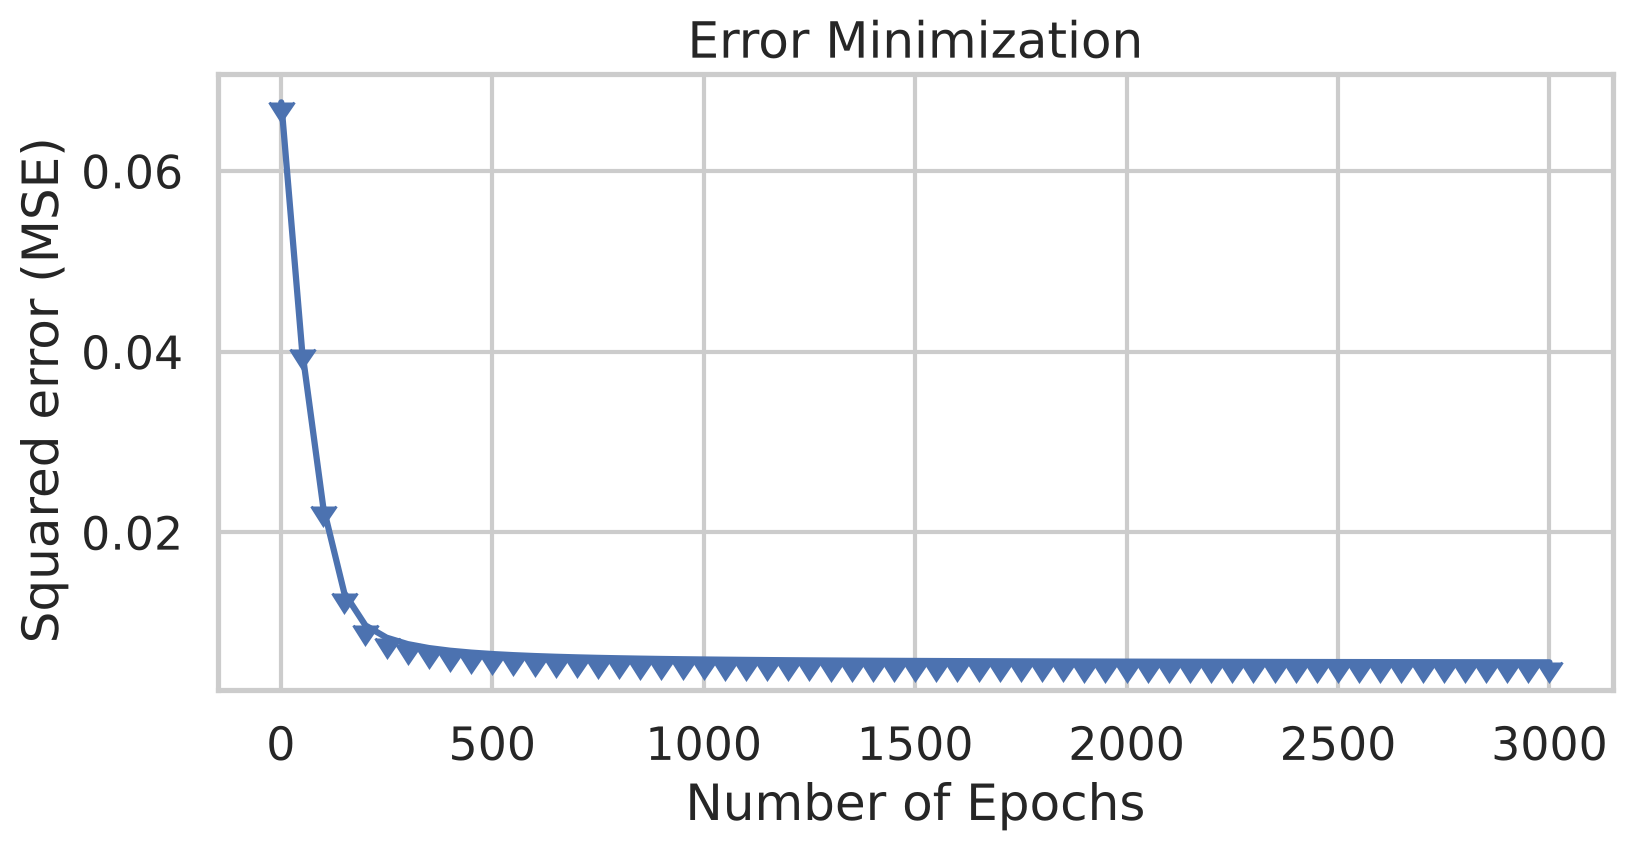

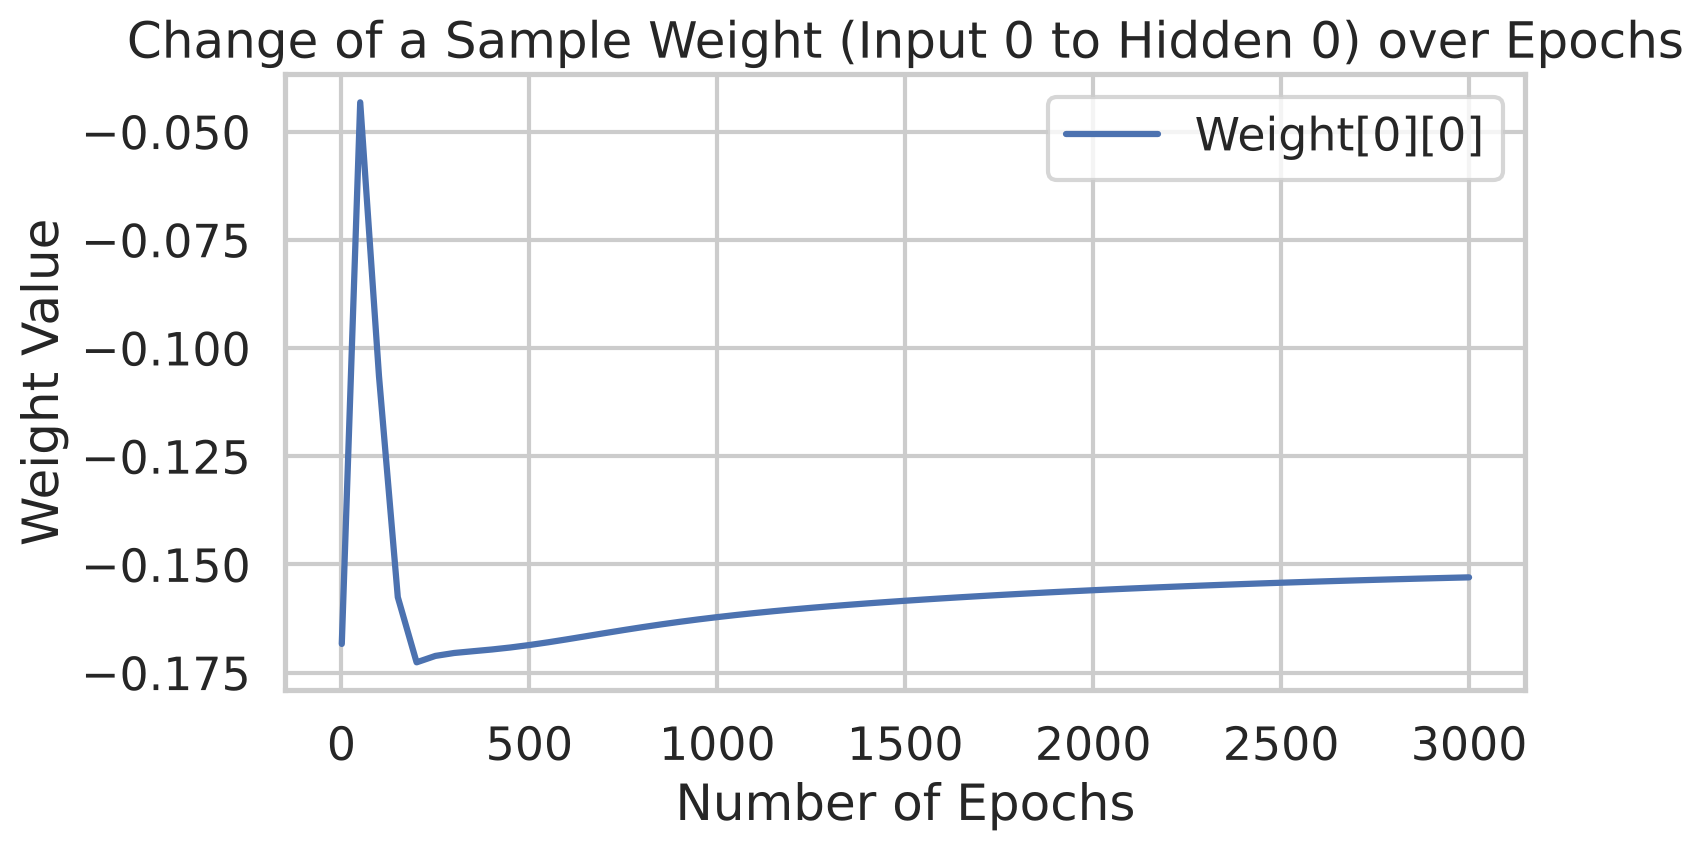

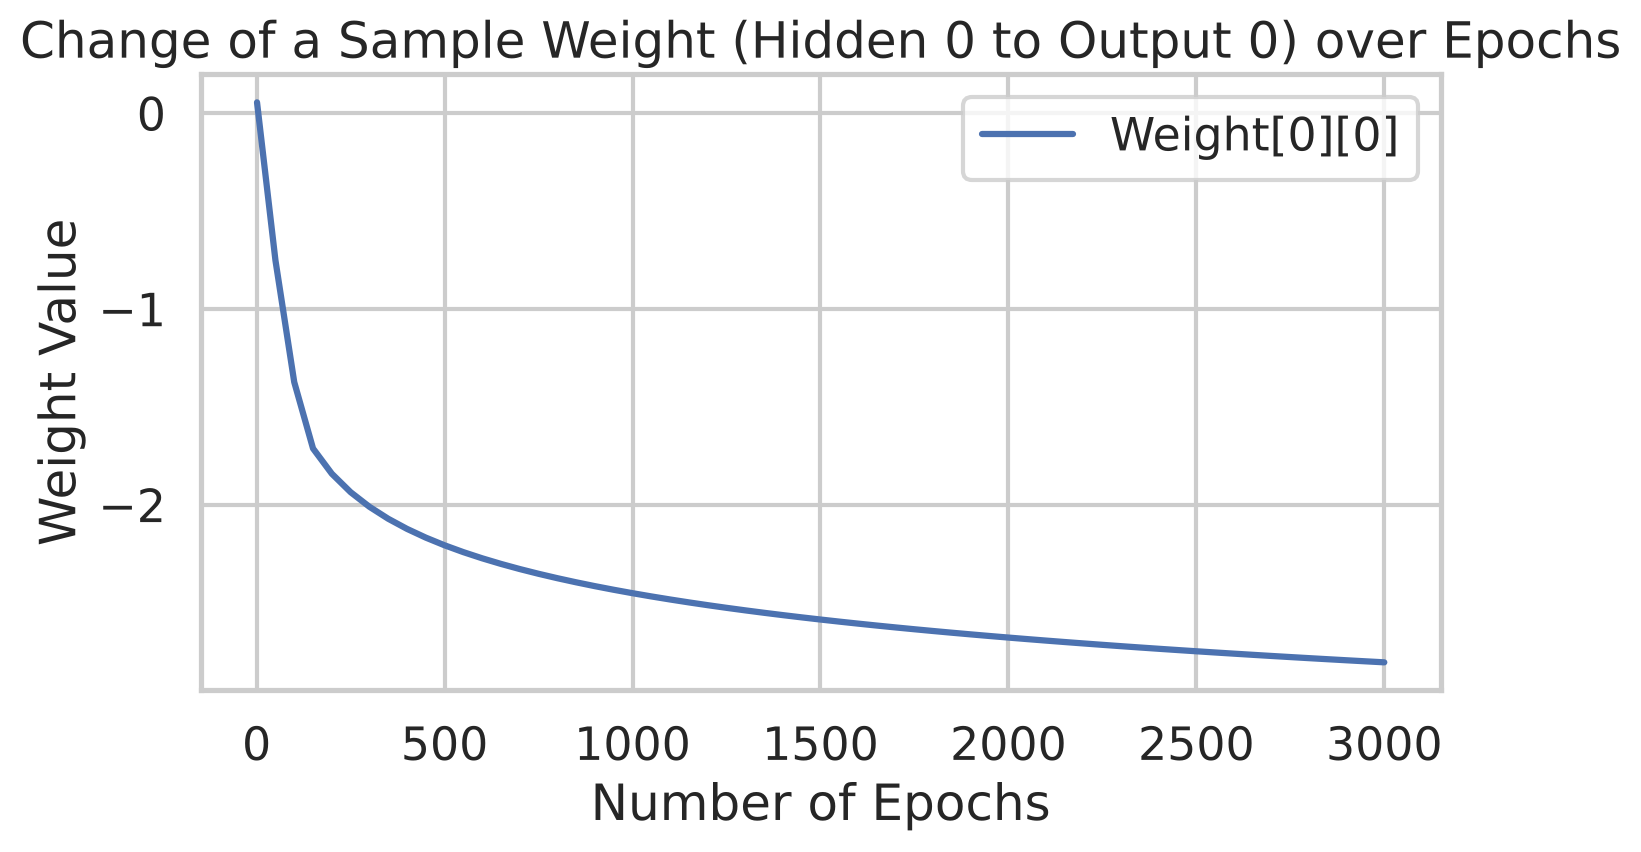

,params,"{'ActivationFunction': 'sigmoid', 'BiasHiddenValue': -1, 'BiasOutputValue': -1, 'Epocas': 3000, ...}"


In [10]:
dictionary = {'InputLayer':4, 'HiddenLayer':5, 'OutputLayer':3,
              'Epocas':3000, 'LearningRate':0.005,'BiasHiddenValue':-1,
              'BiasOutputValue':-1, 'ActivationFunction':'sigmoid'}

Perceptron = MultiLayerPerceptron(dictionary)
Perceptron.fit(train_X,train_y)

In [11]:
prev, dataframe = Perceptron.predict(test_X, test_y)
hits = n_set = n_vers = n_virg = 0
score_set = score_vers = score_virg = 0
for j in range(len(test_y)):
    if(test_y[j] == 0): n_set += 1
    elif(test_y[j] == 1): n_vers += 1
    elif(test_y[j] == 2): n_virg += 1

for i in range(len(test_y)):
    if test_y[i] == prev[i]:
        hits += 1
    if test_y[i] == prev[i] and test_y[i] == 0:
        score_set += 1
    elif test_y[i] == prev[i] and test_y[i] == 1:
        score_vers += 1
    elif test_y[i] == prev[i] and test_y[i] == 2:
        score_virg += 1

hits = (hits / len(test_y)) * 100
faults = 100 - hits

print("Porcents :","%.2f"%(hits),"% hits","and","%.2f"%(faults),"% faults")
print("Total samples of test",len(test_y))
print("*Iris-Setosa:",n_set,"samples", score_set, "hits")
print("*Iris-Versicolour:",n_vers,"samples", score_vers, "hits")
print("*Iris-Virginica:",n_virg,"samples", score_virg, "hits")

Porcents : 96.67 % hits and 3.33 % faults
Total samples of test 30
*Iris-Setosa: 20 samples 20 hits
*Iris-Versicolour: 9 samples 9 hits
*Iris-Virginica: 1 samples 0 hits


In [12]:
dataframe

,_id,class,output,hoped_output
0,0,Iris-setosa,0,0.0
1,1,Iris-setosa,0,0.0
2,2,Iris-setosa,0,0.0
3,3,Iris-versicolour,1,1.0
4,4,Iris-versicolour,1,1.0
5,5,Iris-setosa,0,0.0
6,6,Iris-versicolour,1,1.0
7,7,Iris-setosa,0,0.0
8,8,Iris-versicolour,1,1.0
9,9,Iris-setosa,0,0.0


- Acurracy Iris-Setosa: 100.00 %
- Acurracy Iris-Versicolour: 100.00 %
- Acurracy Iris-Virginica: 0.00 %


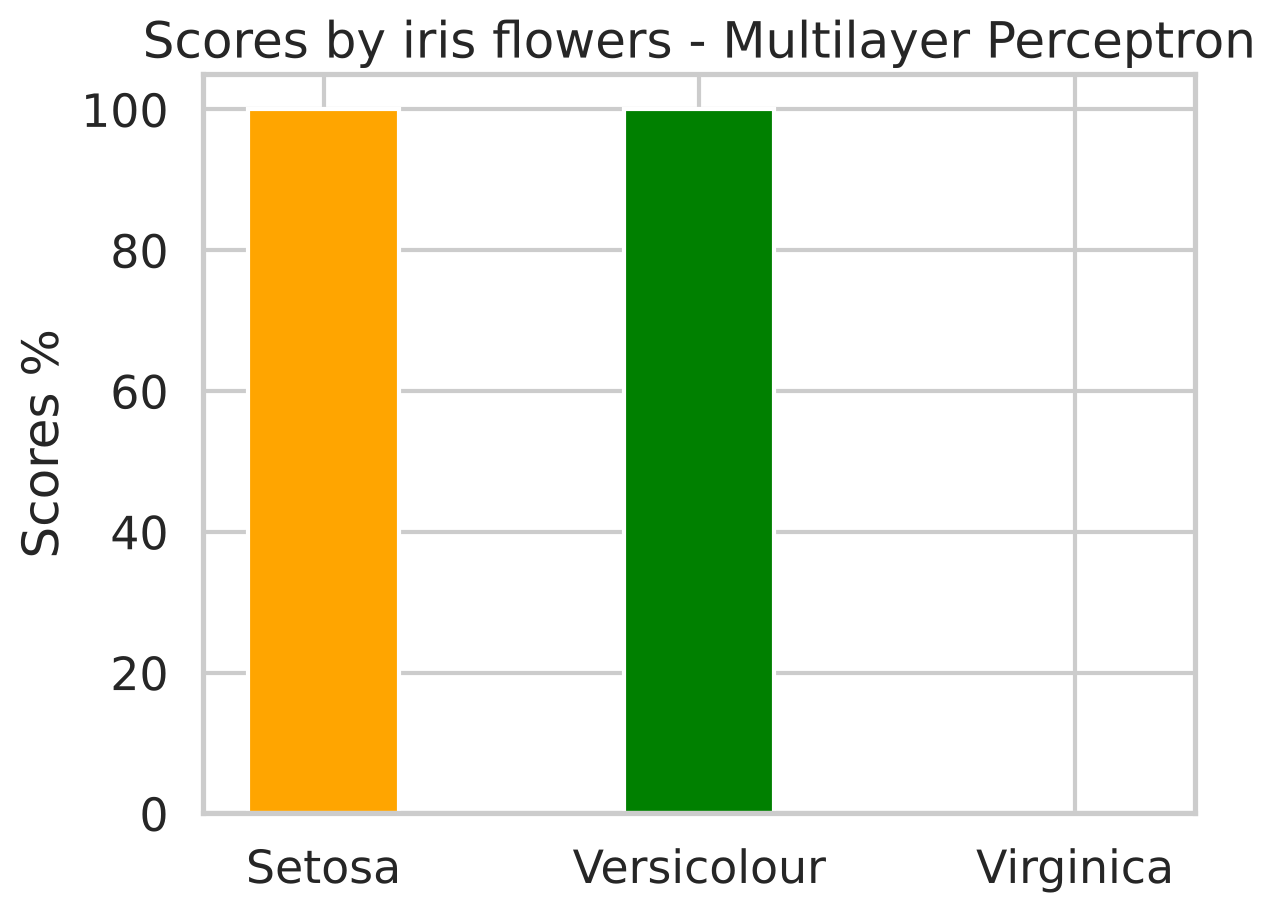

In [13]:
acc_set = (score_set/n_set)*100
acc_vers = (score_vers/n_vers)*100
acc_virg = (score_virg/n_virg)*100
print("- Acurracy Iris-Setosa:","%.2f"%acc_set, "%")
print("- Acurracy Iris-Versicolour:","%.2f"%acc_vers, "%")
print("- Acurracy Iris-Virginica:","%.2f"%acc_virg, "%")
names = ["Setosa","Versicolour","Virginica"]
x1 = [2.0,4.0,6.0]
fig, ax = plt.subplots()
r1 = plt.bar(x1[0], acc_set,color='orange',label='Iris-Setosa')
r2 = plt.bar(x1[1], acc_vers,color='green',label='Iris-Versicolour')
r3 = plt.bar(x1[2], acc_virg,color='purple',label='Iris-Virginica')
plt.ylabel('Scores %')
plt.xticks(x1, names);plt.title('Scores by iris flowers - Multilayer Perceptron')
plt.show()

---
## Parte 2 — Depuração

Configuração comum para o restante do notebook: estilo de gráfico, pasta de figuras e um dicionário `R` com os resultados numéricos que vão para o artigo.

In [14]:
import os, io, json, time, contextlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

FIG_DIR = 'figuras'
os.makedirs(FIG_DIR, exist_ok=True)
R = {}   # resultados numéricos (exportados para resultados.json no final)

# estilo sóbrio para as figuras do artigo (desfaz o seaborn 'talk' do notebook original)
mpl.rcdefaults()
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 9, 'axes.titlesize': 9.5,
    'axes.labelsize': 9, 'legend.fontsize': 8, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': '#e4e3df', 'grid.linewidth': 0.6, 'axes.edgecolor': '#8a8984',
    'axes.axisbelow': True, 'lines.linewidth': 1.5, 'legend.frameon': False,
})
# paleta categórica validada (ordem fixa) e cor neutra
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
GRAY = '#8a8984'
CLASS_NAMES = ['setosa', 'versicolor', 'virginica']

def salvar(fig, nome):
    fig.savefig(f'{FIG_DIR}/{nome}.pdf', bbox_inches='tight')
    fig.savefig(f'{FIG_DIR}/{nome}.png', bbox_inches='tight')

@contextlib.contextmanager
def silencioso():
    """Suprime prints e gráficos internos da classe original."""
    show = plt.show
    plt.show = lambda *a, **k: plt.close('all')
    try:
        with contextlib.redirect_stdout(io.StringIO()):
            yield
    finally:
        plt.show = show

### Bug 1 (crítico): `random.shuffle` corrompe o array NumPy

`random.shuffle` (da biblioteca padrão do Python) troca elementos com `x[i], x[j] = x[j], x[i]`. Em um array NumPy 2D, `x[j]` é uma **view** (referência) da linha, não uma cópia. A atribuição `x[i] = x[j]` copia a linha *j* sobre a linha *i*, e em seguida `x[j] = (view antiga de x[i])` copia de volta o conteúdo **já sobrescrito**. Resultado: a linha *i* original some e a linha *j* fica duplicada. Repetido 149 vezes, isso destrói o conjunto de dados.

In [15]:
# demonstração mínima
a = np.arange(10).reshape(5, 2)
random.seed(0); random.shuffle(a)
print("array 5x2 após random.shuffle:\n", a)

# efeito no dataset usado pelo notebook original
cont_corromp = np.bincount(iris_dataset[:, 4].astype(int), minlength=3)
n_unicas = len(np.unique(iris_dataset, axis=0))
print("\nClasses no dataset 'embaralhado':", dict(zip(CLASS_NAMES, cont_corromp)))
print("Linhas distintas:", n_unicas, "de", len(iris_dataset))
print("Treino:", np.bincount(train_y.astype(int), minlength=3), " Teste:", np.bincount(test_y.astype(int), minlength=3))
R['shuffle'] = {'classes': cont_corromp.tolist(), 'linhas_unicas': int(n_unicas),
                'treino': np.bincount(train_y.astype(int), minlength=3).tolist(),
                'teste': np.bincount(test_y.astype(int), minlength=3).tolist()}

array 5x2 após random.shuffle:
 [[0 1]
 [2 3]
 [0 1]
 [6 7]
 [6 7]]

Classes no dataset 'embaralhado': {'setosa': np.int64(102), 'versicolor': np.int64(42), 'virginica': np.int64(6)}
Linhas distintas: 74 de 150
Treino: [82 33  5]  Teste: [20  9  1]


**Correção:** não embaralhar manualmente. Basta usar `train_test_split(..., shuffle=True, stratify=y)`, que já embaralha. Se for preciso embaralhar, use índices: `X[rng.permutation(len(X))]` ou `np.random.shuffle`, que trata arrays corretamente.

Treino: [40 40 40]  Teste: [10 10 10]


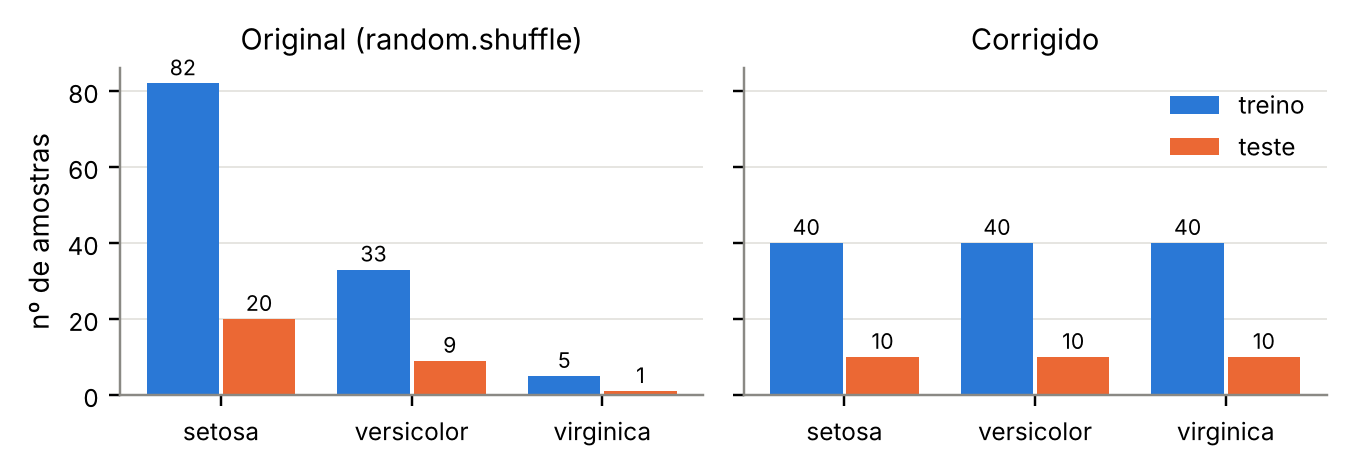

In [16]:
iris = load_iris()
X_all, y_all = iris.data, iris.target
Xtr, Xte, ytr, yte = train_test_split(X_all, y_all, test_size=0.2, random_state=11, stratify=y_all)
print("Treino:", np.bincount(ytr), " Teste:", np.bincount(yte))

fig, axs = plt.subplots(1, 2, figsize=(6.2, 2.2), sharey=True)
w = 0.38
for ax, (titulo, tr, te) in zip(axs, [("Original (random.shuffle)", R['shuffle']['treino'], R['shuffle']['teste']),
                                       ("Corrigido", np.bincount(ytr).tolist(), np.bincount(yte).tolist())]):
    x = np.arange(3)
    b1 = ax.bar(x - w/2 - 0.01, tr, w, color=C[0], label='treino')
    b2 = ax.bar(x + w/2 + 0.01, te, w, color=C[1], label='teste')
    ax.bar_label(b1, fontsize=7, padding=1); ax.bar_label(b2, fontsize=7, padding=1)
    ax.set_xticks(x, CLASS_NAMES); ax.set_title(titulo); ax.grid(axis='x', visible=False)
axs[0].set_ylabel('nº de amostras'); axs[1].legend(loc='upper right')
fig.tight_layout(); salvar(fig, 'distribuicao_classes'); plt.show()

### Bug 2 (crítico): os bias são inteiros e nunca são aprendidos

`np.array([-1 for i in range(n)])` cria um array de **`int64`**. A atualização `self.BIAS_output[j] -= lr * delta` calcula um valor real (ex.: −0,997) e o grava truncado num inteiro. Na prática o bias fica preso em −1 ou, na primeira atualização positiva, salta para **0** e ali permanece (−0,003 → 0; +0,003 → 0).

In [17]:
print("dtype dos bias:", Perceptron.BIAS_hidden.dtype)
print("BIAS_hidden após 3000 épocas:", Perceptron.BIAS_hidden)
print("BIAS_output após 3000 épocas:", Perceptron.BIAS_output)
b = np.array([-1, -1]); b[0] -= 0.005 * 0.6; b[1] -= 0.005 * (-0.6)
print("demonstração: [-1,-1] após -= ±0.003 ->", b)
R['bias_final'] = {'hidden': Perceptron.BIAS_hidden.tolist(), 'output': Perceptron.BIAS_output.tolist()}

dtype dos bias: int64
BIAS_hidden após 3000 épocas: [0 0 0 0 0]
BIAS_output após 3000 épocas: [0 0 0]
demonstração: [-1,-1] após -= ±0.003 -> [-1  0]


### Bugs 3 e 4: atualização do bias no laço errado e ordem do backpropagation

```python
for i in range(self.hiddenLayer):
    for j in range(self.outputLayer):
        self.WEIGHT_output[i][j] -= ...
        self.BIAS_output[j] -= (self.learningRate * DELTA_output[j])   # <- dentro do laço de i
```

* O bias de saída é atualizado `hiddenLayer` vezes (5×) por amostra e o oculto `inputLayer` vezes (4×). Isso equivale a usar uma taxa de aprendizado diferente para o bias. Esse bug ficava mascarado pelo Bug 2.
* O delta da camada oculta (`Stage 3`) é calculado com `self.WEIGHT_output` **já atualizado** no `Stage 2`. O gradiente correto usa os pesos antes da atualização. O efeito é pequeno com taxa baixa, mas o algoritmo deixa de ser o backpropagation exato.

### Bug 5 (crítico): `predict()` não aplica as funções de ativação

```python
forward = np.matmul(X, self.WEIGHT_hidden) + self.BIAS_hidden          # falta sigmoid
forward = np.matmul(forward, self.WEIGHT_output) + self.BIAS_output     # falta sigmoid
```

A rede é treinada com sigmoide, mas avaliada como uma composição de duas transformações **lineares**. A falta da sigmoide na saída não muda o `argmax`, porque ela é monotônica. Já a falta na camada oculta muda completamente a função calculada. Abaixo, os mesmos pesos treinados avaliados das duas formas. Neste caso particular as duas coincidem (96,7%), mas isso é coincidência: no **Experimento 1**, com os dados corretos, o `predict` original cai para 63–67% enquanto o *forward* correto acerta 100%.

In [18]:
sig = lambda z: 1 / (1 + np.exp(-z))
def forward_correto(m, X):
    h = sig(np.dot(X, m.WEIGHT_hidden) + m.BIAS_hidden)
    return sig(np.dot(h, m.WEIGHT_output) + m.BIAS_output).argmax(1)

p_orig, _ = Perceptron.predict(test_X, test_y)
print("Teste (dados corrompidos) - predict original :", np.mean(np.array(p_orig) == test_y))
print("Teste (dados corrompidos) - forward com sigmoide:", np.mean(forward_correto(Perceptron, test_X) == test_y))

Teste (dados corrompidos) - predict original : 0.9666666666666667
Teste (dados corrompidos) - forward com sigmoide: 0.9666666666666667


### Bug 6: o "Total Error" não é um MSE

```python
for i in range(self.outputLayer):
    erro = (self.output[i] - self.OUTPUT_L2[i])**2
    square_error = (square_error + (0.05 * erro))
    total_error = total_error + square_error        # soma a soma parcial a cada i
```

`total_error` acumula as **somas parciais** (e₀, e₀+e₁, e₀+e₁+e₂), ou seja, 0,05·(3e₀ + 2e₁ + e₂), com um fator 0,05 arbitrário. A curva até cai quando o erro cai, mas os valores não podem ser interpretados nem comparados entre configurações.

In [19]:
def total_error_original(m, X, y):
    tot = 0
    for x, t in zip(X, y):
        o = sig(np.dot(sig(np.dot(x, m.WEIGHT_hidden) + m.BIAS_hidden), m.WEIGHT_output) + m.BIAS_output)
        T = np.eye(3)[int(t)]; se = 0
        for i in range(3):
            se += 0.05 * (T[i] - o[i]) ** 2; tot += se
    return tot / len(X)
def mse(m, X, y):
    h = sig(np.dot(X, m.WEIGHT_hidden) + m.BIAS_hidden); o = sig(np.dot(h, m.WEIGHT_output) + m.BIAS_output)
    return np.mean((np.eye(3)[y.astype(int)] - o) ** 2)
print("'Total Error' do original:", total_error_original(Perceptron, train_X, train_y))
print("MSE verdadeiro           :", mse(Perceptron, train_X, train_y))

'Total Error' do original: 0.00559698501504497
MSE verdadeiro           : 0.024550283960591536


### Bug 7 e outros problemas

* **Construtor padrão quebrado:** com `params=None`, a linha `self.iasHiddenValue = -1` (falta o *B*) faz o construtor lançar `AttributeError`.
* `if (params == None)` deveria ser `if params is None`.
* Sem normalização das entradas, sem conjunto de validação e com o conjunto de teste usado como única avaliação. Não há como analisar *overfitting*.
* As amostras são apresentadas sempre na mesma ordem em todas as épocas, e os pesos ficam em listas Python com laços duplos, o que deixa o treino lento.
* O gráfico de erro só registra uma época a cada 50.

In [20]:
try:
    MultiLayerPerceptron()
except AttributeError as e:
    print("MultiLayerPerceptron() ->", type(e).__name__ + ":", e)

MultiLayerPerceptron() -> AttributeError: 'MultiLayerPerceptron' object has no attribute 'BiasHiddenValue'


| # | Problema | Onde | Gravidade | Efeito |
|---|---|---|---|---|
| 1 | `random.shuffle` em array NumPy duplica/apaga linhas | preparação dos dados | **crítico** | 74/150 linhas únicas; 102/42/6 amostras por classe; 1 virginica no teste |
| 2 | bias `int64` (truncamento) | `__init__` | **crítico** | bias nunca aprendidos (presos em 0) |
| 3 | bias atualizado dentro do laço dos pesos | `Backpropagation_Algorithm` | médio | passo do bias 4–5× maior |
| 4 | delta oculto com pesos já atualizados | `Backpropagation_Algorithm` | baixo | gradiente inexato |
| 5 | `predict` sem ativação | `predict` | **crítico** | avalia uma rede linear diferente da treinada |
| 6 | "Total Error" com somas parciais e fator 0,05 | `fit` | médio | curva de erro sem significado |
| 7 | `iasHiddenValue` | `__init__` | baixo | construtor padrão falha |

---
## Parte 3 — Implementação corrigida

A classe abaixo mantém a interface do original (mesmo dicionário de parâmetros, mesmos nomes `WEIGHT_hidden`, `BIAS_output`, `Backpropagation_Algorithm`…), corrige os bugs 2–7 e acrescenta: histórico de erro e acurácia **a cada época** (treino e validação), semente própria, embaralhamento por época, *early stopping* opcional, ativação de saída independente e a opção de *softmax* + entropia cruzada. O backpropagation foi vetorizado com NumPy, mas continua sendo SGD amostra a amostra (`BatchSize=1`), como no original.

In [21]:
from sklearn.base import BaseEstimator, ClassifierMixin

class MultiLayerPerceptronFixed(BaseEstimator, ClassifierMixin):
    """MLP de 1 camada oculta, treinado por backpropagation (SGD).

    Mantém a interface de parâmetros do notebook original (dicionário com as
    mesmas chaves), com as correções:
      * bias em float (no original eram int e nunca eram aprendidos);
      * bias atualizado uma vez por amostra (no original ficava dentro do laço
        dos pesos e era atualizado 4-5 vezes);
      * delta da camada oculta calculado com os pesos de saída ANTES da
        atualização (backprop correto);
      * predict() aplica as funções de ativação (no original a rede era
        avaliada como se fosse linear);
      * MSE calculado corretamente e registrado a cada época, junto com a
        acurácia e, opcionalmente, o erro/acurácia em um conjunto de validação;
      * semente própria (resultados reprodutíveis) e embaralhamento dos
        exemplos a cada época.
    Extras opcionais: 'OutputActivation' (ativação da saída independente da
    oculta), 'Loss' = 'mse' (original) ou 'ce' (softmax + entropia cruzada),
    'BatchSize' (1 = SGD online, como no original).
    """

    ativacao = {
        'sigmoid': lambda x: 1.0 / (1.0 + np.exp(-x)),
        'tanh':    lambda x: np.tanh(x),
        'Relu':    lambda x: x * (x > 0),
    }
    # derivadas escritas em função da SAÍDA do neurônio (a = f(z))
    derivada = {
        'sigmoid': lambda a: a * (1.0 - a),
        'tanh':    lambda a: 1.0 - a ** 2,
        'Relu':    lambda a: 1.0 * (a > 0),
    }

    def __init__(self, params=None):
        self.params = params

    # ------------------------------------------------------------------ setup
    def _setup(self):
        p = {'InputLayer': 4, 'HiddenLayer': 5, 'OutputLayer': 3,
             'LearningRate': 0.005, 'Epocas': 600,
             'BiasHiddenValue': -1, 'BiasOutputValue': -1,
             'ActivationFunction': 'sigmoid', 'OutputActivation': None,
             'Loss': 'mse', 'BatchSize': 1, 'Shuffle': True, 'Seed': 0,
             'InitBias': 'constant'}
        if self.params is not None:
            p.update(self.params)
        self.p_ = p
        self.inputLayer = p['InputLayer']
        self.hiddenLayer = p['HiddenLayer']
        self.outputLayer = p['OutputLayer']
        self.learningRate = p['LearningRate']
        self.max_epochs = p['Epocas']
        self.loss = p['Loss']
        hid = p['ActivationFunction']
        out = p['OutputActivation'] or hid
        if self.loss == 'ce':
            out = 'softmax'
        self.hid_name, self.out_name = hid, out
        self.activation = self.ativacao[hid]
        self.deriv = self.derivada[hid]
        self.rng = np.random.default_rng(p['Seed'])

        # pesos uniformes em [-1, 1] como no original
        self.WEIGHT_hidden = self.rng.uniform(-1, 1, (self.inputLayer, self.hiddenLayer))
        self.WEIGHT_output = self.rng.uniform(-1, 1, (self.hiddenLayer, self.outputLayer))
        if p['InitBias'] == 'random':
            self.BIAS_hidden = self.rng.uniform(-1, 1, self.hiddenLayer)
            self.BIAS_output = self.rng.uniform(-1, 1, self.outputLayer)
        else:  # valor constante, mas agora em float
            self.BIAS_hidden = np.full(self.hiddenLayer, float(p['BiasHiddenValue']))
            self.BIAS_output = np.full(self.outputLayer, float(p['BiasOutputValue']))
        self.classes_ = np.arange(self.outputLayer)

    # ---------------------------------------------------------------- forward
    def _out_act(self, z):
        if self.out_name == 'softmax':
            z = z - z.max(axis=-1, keepdims=True)
            e = np.exp(z)
            return e / e.sum(axis=-1, keepdims=True)
        return self.ativacao[self.out_name](z)

    def forward(self, X):
        A1 = self.activation(X @ self.WEIGHT_hidden + self.BIAS_hidden)
        A2 = self._out_act(A1 @ self.WEIGHT_output + self.BIAS_output)
        return A1, A2

    def _onehot(self, y):
        T = np.zeros((len(y), self.outputLayer))
        T[np.arange(len(y)), np.asarray(y, dtype=int)] = 1.0
        return T

    def loss_value(self, X, y):
        _, A2 = self.forward(X)
        T = self._onehot(y)
        if self.loss == 'ce':
            return float(-np.mean(np.sum(T * np.log(A2 + 1e-12), axis=1)))
        return float(np.mean((T - A2) ** 2))          # MSE "de verdade"

    # --------------------------------------------------------------- backprop
    def gradients(self, X, T):
        """Gradientes (média no lote) de L = 0.5*sum_k (t_k - o_k)^2 (MSE)
        ou da entropia cruzada (softmax)."""
        A1, A2 = self.forward(X)
        if self.loss == 'ce':
            delta_out = A2 - T
        else:
            delta_out = (A2 - T) * self.derivada[self.out_name](A2)
        # delta oculto com os pesos de saída ANTES da atualização
        delta_hid = (delta_out @ self.WEIGHT_output.T) * self.deriv(A1)
        n = X.shape[0]
        gW2 = A1.T @ delta_out / n
        gb2 = delta_out.sum(axis=0) / n
        gW1 = X.T @ delta_hid / n
        gb1 = delta_hid.sum(axis=0) / n
        return gW1, gb1, gW2, gb2

    def Backpropagation_Algorithm(self, X, T):
        gW1, gb1, gW2, gb2 = self.gradients(X, T)
        lr = self.learningRate
        self.WEIGHT_output -= lr * gW2
        self.BIAS_output -= lr * gb2      # uma vez por amostra / lote
        self.WEIGHT_hidden -= lr * gW1
        self.BIAS_hidden -= lr * gb1

    # -------------------------------------------------------------------- fit
    def fit(self, X, y, X_val=None, y_val=None, verbose=0, early_stopping=None):
        """early_stopping = paciência (nº de épocas sem melhora do erro de
        validação); restaura os melhores pesos."""
        self._setup()
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).astype(int)
        T = self._onehot(y)
        n = len(X)
        bs = self.p_['BatchSize'] or n
        self.history_ = {'epoch': [], 'train_loss': [], 'train_acc': [],
                         'train_mse': [], 'val_loss': [], 'val_acc': []}
        best = (np.inf, None, 0)
        for epoch in range(1, self.max_epochs + 1):
            idx = self.rng.permutation(n) if self.p_['Shuffle'] else np.arange(n)
            for s in range(0, n, bs):
                b = idx[s:s + bs]
                self.Backpropagation_Algorithm(X[b], T[b])
            h = self.history_
            h['epoch'].append(epoch)
            h['train_loss'].append(self.loss_value(X, y))
            h['train_mse'].append(float(np.mean((T - self.predict_proba(X)) ** 2)))
            h['train_acc'].append(float(np.mean(self.predict(X) == y)))
            if X_val is not None:
                vl = self.loss_value(X_val, y_val)
                h['val_loss'].append(vl)
                h['val_acc'].append(float(np.mean(self.predict(X_val) == np.asarray(y_val).astype(int))))
                if early_stopping is not None:
                    if vl < best[0] - 1e-6:
                        best = (vl, self._get_weights(), epoch)
                    elif epoch - best[2] >= early_stopping:
                        break
            if not np.isfinite(h['train_loss'][-1]):
                break
            if verbose and (epoch % verbose == 0 or epoch == 1):
                msg = f"Época {epoch:5d} - MSE treino: {h['train_loss'][-1]:.5f} - acc treino: {h['train_acc'][-1]:.3f}"
                if X_val is not None:
                    msg += f" | val: {h['val_loss'][-1]:.5f} / {h['val_acc'][-1]:.3f}"
                print(msg)
        if early_stopping is not None and best[1] is not None:
            self._set_weights(best[1])
            self.best_epoch_ = best[2]
        return self

    def _get_weights(self):
        return [w.copy() for w in (self.WEIGHT_hidden, self.BIAS_hidden,
                                   self.WEIGHT_output, self.BIAS_output)]

    def _set_weights(self, w):
        self.WEIGHT_hidden, self.BIAS_hidden, self.WEIGHT_output, self.BIAS_output = [x.copy() for x in w]

    # ---------------------------------------------------------------- predict
    def predict_proba(self, X):
        return self.forward(np.asarray(X, dtype=float))[1]

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

    def predict_dataframe(self, X, y):
        names = {0: 'Iris-setosa', 1: 'Iris-versicolour', 2: 'Iris-virginica'}
        pred = self.predict(X)
        return pd.DataFrame({'_id': np.arange(len(pred)),
                             'class': [names[k] for k in pred],
                             'output': pred,
                             'hoped_output': np.asarray(y).astype(int)})


MLP = MultiLayerPerceptronFixed

### Verificação do gradiente (*gradient check*)

Comparamos o gradiente analítico do backpropagation com diferenças finitas centradas, $\frac{L(\theta+\varepsilon)-L(\theta-\varepsilon)}{2\varepsilon}$, para todos os pesos e bias. Erros relativos da ordem de $10^{-7}$ ou menores indicam implementação correta.

In [22]:
def gradient_check(params, X, y, eps=1e-6):
    m = MLP(params); m._setup()
    T = m._onehot(y)
    def L():
        _, A2 = m.forward(X)
        if m.loss == 'ce':
            return -np.mean(np.sum(T * np.log(A2), 1))
        return np.mean(0.5 * np.sum((T - A2) ** 2, 1))
    analit = m.gradients(X, T)
    out = []
    for P, G in zip([m.WEIGHT_hidden, m.BIAS_hidden, m.WEIGHT_output, m.BIAS_output], analit):
        num = np.zeros_like(P)
        for i in np.ndindex(P.shape):
            old = P[i]; P[i] = old + eps; lp = L(); P[i] = old - eps; lm = L(); P[i] = old
            num[i] = (lp - lm) / (2 * eps)
        out.append(np.max(np.abs(num - G)) / np.max(np.abs(num)))
    return out

gc = {}
for act, out, loss in [('sigmoid', 'sigmoid', 'mse'), ('tanh', 'sigmoid', 'mse'), ('Relu', 'sigmoid', 'mse'), ('sigmoid', None, 'ce')]:
    e = gradient_check({'ActivationFunction': act, 'OutputActivation': out, 'Loss': loss, 'Seed': 3, 'InitBias': 'random'},
                       Xtr[:10], ytr[:10])
    nome = f"{act}/{out or 'softmax'}/{loss}"
    gc[nome] = max(e)
    print(f"{nome:24s} erro relativo máx. (W1, b1, W2, b2): " + "  ".join(f"{v:.1e}" for v in e))
R['gradient_check_max'] = max(gc.values())

sigmoid/sigmoid/mse      erro relativo máx. (W1, b1, W2, b2): 2.3e-09  9.5e-09  4.5e-10  2.4e-10
tanh/sigmoid/mse         erro relativo máx. (W1, b1, W2, b2): 5.2e-10  1.5e-09  1.9e-09  2.1e-10
Relu/sigmoid/mse         erro relativo máx. (W1, b1, W2, b2): 2.3e-10  8.4e-10  1.6e-10  7.1e-10
sigmoid/softmax/ce       erro relativo máx. (W1, b1, W2, b2): 1.1e-09  3.1e-09  1.2e-09  6.3e-11


---
## Parte 4 — Experimentos

**Protocolo.** O conjunto de **teste** (30 amostras, 10 por classe, `random_state=11` como no original) fica reservado para a avaliação final. Todas as escolhas de hiperparâmetros usam apenas as 120 amostras de treino:
* **curvas de aprendizado:** divisão estratificada interna em 90 (treino) e 30 (validação);
* **comparações de acurácia:** validação cruzada estratificada de 5 *folds* nas 120 amostras.

A normalização *z-score* (`StandardScaler`) é sempre ajustada só nos dados de treino de cada divisão. Salvo indicação, a configuração-base é 4–5–3, sigmoide, MSE, SGD online e pesos iniciais uniformes em [−1, 1].

In [23]:
Xa, Xv, ya, yv = train_test_split(Xtr, ytr, test_size=0.25, random_state=0, stratify=ytr)
sc_in = StandardScaler().fit(Xa)
Xa_z, Xv_z = sc_in.transform(Xa), sc_in.transform(Xv)
print("treino interno:", np.bincount(ya), " validação:", np.bincount(yv), " teste:", np.bincount(yte))

def epoca_ate(h, chave='train_acc', limiar=0.95):
    a = np.array(h[chave]); i = np.where(a >= limiar)[0]
    return int(i[0]) + 1 if len(i) else np.nan

def cv_acc(params, X=Xtr, y=ytr, n_splits=5, repeats=1, normalizar=True, extra=False):
    """Acurácia de validação cruzada estratificada (média, desvio, lista)."""
    accs, acc_tr = [], []
    for r in range(repeats):
        for k, (a, v) in enumerate(StratifiedKFold(n_splits, shuffle=True, random_state=r).split(X, y)):
            A, V = X[a], X[v]
            if normalizar:
                s = StandardScaler().fit(A); A, V = s.transform(A), s.transform(V)
            m = MLP({**params, 'Seed': 100 * r + k}).fit(A, y[a])
            accs.append(np.mean(m.predict(V) == y[v])); acc_tr.append(np.mean(m.predict(A) == y[a]))
    out = {'media': float(np.mean(accs)), 'desvio': float(np.std(accs)), 'treino': float(np.mean(acc_tr))}
    return out

BASE = {'InputLayer': 4, 'HiddenLayer': 5, 'OutputLayer': 3, 'ActivationFunction': 'sigmoid',
        'BiasHiddenValue': -1, 'BiasOutputValue': -1}

treino interno: [30 30 30]  validação: [10 10 10]  teste: [10 10 10]


### Experimento 1 — Efeito das correções

Treinamos o código **original** nos dados corretos (3 sementes, 3000 épocas, lr = 0,005, os mesmos hiperparâmetros do notebook) e avaliamos os mesmos pesos com o `predict` original e com o *forward* correto. Depois treinamos o código **corrigido** com os mesmos hiperparâmetros e, por fim, com a configuração escolhida nos experimentos seguintes (z-score, lr = 0,1, 300 épocas).

In [24]:
t0 = time.time()
ablacao = {'orig_pred_orig': [], 'orig_pred_ok': [], 'orig_bias': [], 'fix_mesmos_hp': [], 'fix_final': []}
for seed in [0, 1, 2]:
    random.seed(seed)
    m = MultiLayerPerceptron(dictionary)          # classe ORIGINAL
    with silencioso():
        m.fit(Xtr, ytr.astype(float))
    p, _ = m.predict(Xte, yte)
    ablacao['orig_pred_orig'].append(np.mean(np.array(p) == yte))
    ablacao['orig_pred_ok'].append(np.mean(forward_correto(m, Xte) == yte))
    ablacao['orig_bias'].append(m.BIAS_hidden.tolist() + m.BIAS_output.tolist())

    m2 = MLP({**BASE, 'Epocas': 3000, 'LearningRate': 0.005, 'Seed': seed}).fit(Xtr, ytr)
    ablacao['fix_mesmos_hp'].append(np.mean(m2.predict(Xte) == yte))

    s = StandardScaler().fit(Xtr)
    m3 = MLP({**BASE, 'Epocas': 300, 'LearningRate': 0.1, 'Seed': seed}).fit(s.transform(Xtr), ytr)
    ablacao['fix_final'].append(np.mean(m3.predict(s.transform(Xte)) == yte))
print(f"({time.time()-t0:.0f}s)")

acc_nb_original = np.mean(np.array(p_orig) == test_y)
tab = pd.DataFrame({
    'Configuração': ['Notebook original (dados corrompidos)',
                     'Código original, dados corretos, predict original',
                     'Código original, dados corretos, forward com sigmoide',
                     'Código corrigido, mesmos hiperparâmetros',
                     'Código corrigido, z-score, lr=0,1, 300 épocas'],
    'Acurácia de teste por semente': [f"{acc_nb_original:.3f} (1 execução)"] +
        [" / ".join(f"{v:.3f}" for v in ablacao[k]) for k in ['orig_pred_orig', 'orig_pred_ok', 'fix_mesmos_hp', 'fix_final']],
})
display(tab)
print("bias finais do código original (3 sementes):", ablacao['orig_bias'])
R['ablacao'] = {k: [float(x) for x in v] for k, v in ablacao.items() if k != 'orig_bias'}
R['ablacao']['nb_original'] = float(acc_nb_original)

(132s)


,Configuração,Acurácia de teste por semente
0,Notebook original (dados corrompidos),0.967 (1 execução)
1,"Código original, dados corretos, predict original",0.667 / 0.667 / 0.633
2,"Código original, dados corretos, forward com s...",1.000 / 1.000 / 1.000
3,"Código corrigido, mesmos hiperparâmetros",1.000 / 1.000 / 1.000
4,"Código corrigido, z-score, lr=0,1, 300 épocas",1.000 / 1.000 / 1.000


bias finais do código original (3 sementes): [[0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0]]


### Experimento 2 — Convergência da configuração original corrigida

Código corrigido com os hiperparâmetros originais (entradas sem normalização, lr = 0,005, 3000 épocas), registrando MSE e acurácia a cada época no treino interno e na validação.

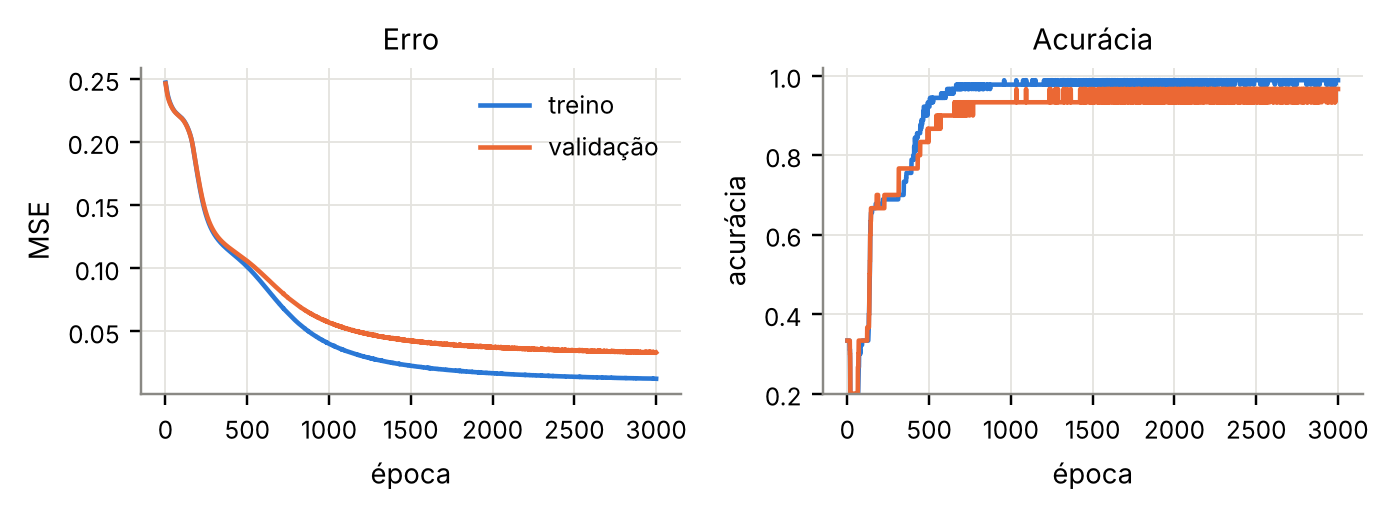

{'ep_70': 312, 'ep_95': 574, 'mse_tr_100': 0.219, 'mse_tr_final': 0.0125, 'mse_val_final': 0.0332, 'acc_tr_final': 0.9889, 'acc_val_final': 0.9667, 'mse_ini': 0.247}


In [25]:
m_base = MLP({**BASE, 'Epocas': 3000, 'LearningRate': 0.005, 'Seed': 0}).fit(Xa, ya, Xv, yv)
h = m_base.history_
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.4))
axs[0].plot(h['epoch'], h['train_loss'], color=C[0], label='treino')
axs[0].plot(h['epoch'], h['val_loss'], color=C[1], label='validação')
axs[0].set_xlabel('época'); axs[0].set_ylabel('MSE'); axs[0].legend(); axs[0].set_title('Erro')
axs[1].plot(h['epoch'], h['train_acc'], color=C[0], label='treino')
axs[1].plot(h['epoch'], h['val_acc'], color=C[1], label='validação')
axs[1].set_xlabel('época'); axs[1].set_ylabel('acurácia'); axs[1].set_ylim(0.2, 1.02); axs[1].set_title('Acurácia')
fig.tight_layout(); salvar(fig, 'convergencia_base'); plt.show()

plat = epoca_ate(h, 'train_acc', 0.70)
R['base'] = {'ep_70': plat, 'ep_95': epoca_ate(h, 'train_acc', 0.95),
             'mse_tr_100': h['train_loss'][99], 'mse_tr_final': h['train_loss'][-1], 'mse_val_final': h['val_loss'][-1],
             'acc_tr_final': h['train_acc'][-1], 'acc_val_final': h['val_acc'][-1], 'mse_ini': h['train_loss'][0]}
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in R['base'].items()})

### Experimento 3 — Normalização das entradas × taxa de aprendizado

Comparação entre entradas brutas (cm) e padronizadas (*z-score*), para lr = 0,005 e lr = 0,05. Mostramos as curvas na divisão interna (semente 0) e a acurácia de validação cruzada (5 *folds*, 600 épocas).

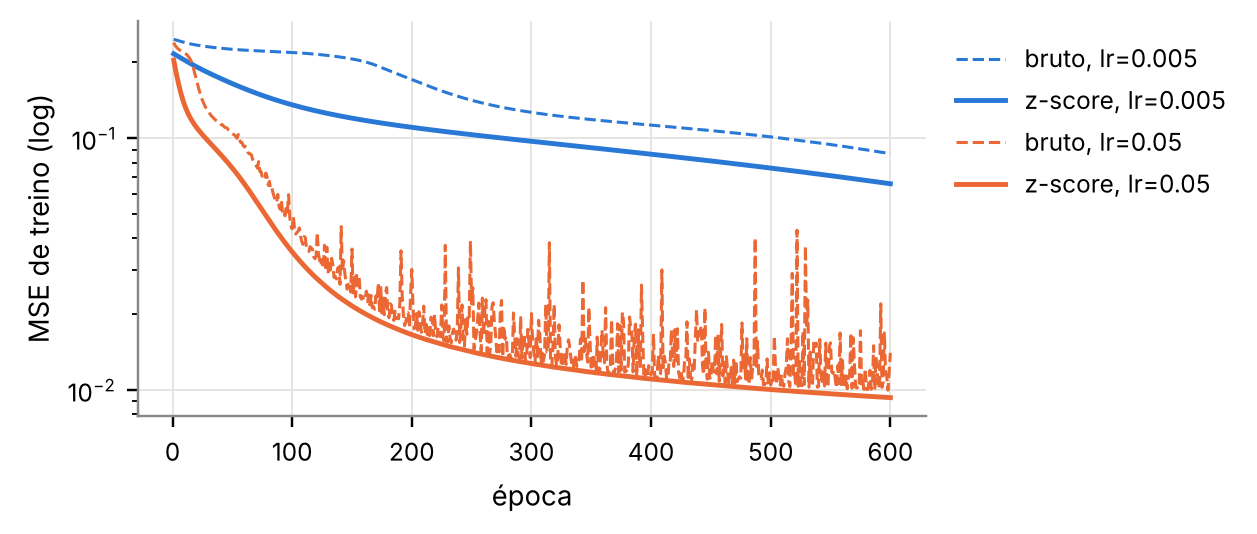

,entrada,lr,época p/ 95% (treino),MSE treino final,acc CV (média),acc CV (desvio)
0,bruto,0.005,574.0,0.0868,0.908,0.125
1,z-score,0.005,NaN,0.0659,0.875,0.091
2,bruto,0.050,42.0,0.0140,0.942,0.033
3,z-score,0.050,64.0,0.0093,0.950,0.041


(68s)


In [26]:
t0 = time.time()
fig, ax = plt.subplots(figsize=(5.8, 2.5))
norm_res = []
for i, (norm, lr) in enumerate([('bruto', 0.005), ('z-score', 0.005), ('bruto', 0.05), ('z-score', 0.05)]):
    A, V = (Xa, Xv) if norm == 'bruto' else (Xa_z, Xv_z)
    m = MLP({**BASE, 'Epocas': 600, 'LearningRate': lr, 'Seed': 0}).fit(A, ya, V, yv)
    ls = '-' if norm == 'z-score' else '--'
    ax.plot(m.history_['epoch'], m.history_['train_loss'], ls, color=C[0] if lr == 0.005 else C[1], label=f'{norm}, lr={lr}',
            lw=1.0 if norm == 'bruto' else 1.6)
    cv = cv_acc({**BASE, 'Epocas': 600, 'LearningRate': lr}, normalizar=(norm == 'z-score'))
    norm_res.append({'entrada': norm, 'lr': lr, 'época p/ 95% (treino)': epoca_ate(m.history_),
                     'MSE treino final': round(m.history_['train_loss'][-1], 4),
                     'acc CV (média)': round(cv['media'], 3), 'acc CV (desvio)': round(cv['desvio'], 3)})
ax.set_yscale('log'); ax.set_xlabel('época'); ax.set_ylabel('MSE de treino (log)')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1.0))
fig.tight_layout(); salvar(fig, 'normalizacao'); plt.show()
df_norm = pd.DataFrame(norm_res); display(df_norm)
R['normalizacao'] = df_norm.to_dict('records'); print(f"({time.time()-t0:.0f}s)")

### Experimento 4 — Taxa de aprendizado

Entradas padronizadas, 500 épocas, 3 sementes. A sigmoide limita a saída, então taxas muito altas não fazem o erro "explodir": elas **saturam** os neurônios (derivada ≈ 0) e o treino trava.

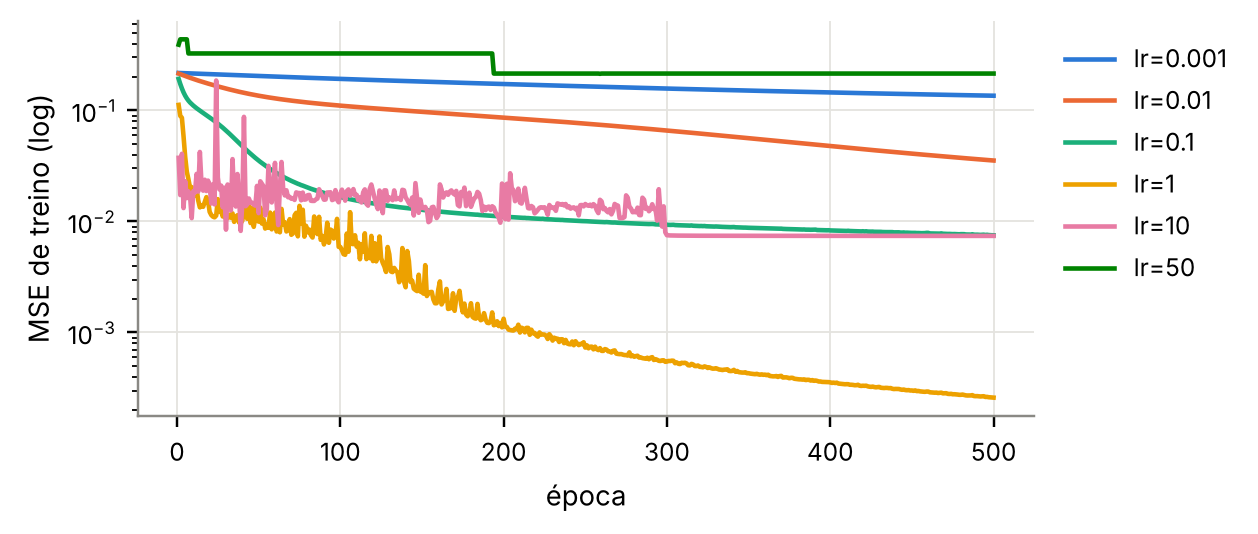

,lr,época p/ 95% (média),sementes que atingem 95%,MSE treino final,acc treino,acc validação
0,0.001,NaN,0,0.1415,0.719,0.722
1,0.010,302.500000,2,0.0387,0.967,0.911
2,0.100,37.666667,3,0.0078,0.985,0.967
3,1.000,5.333333,3,0.0003,1.000,0.956
4,10.000,1.666667,3,0.0070,0.989,0.922
5,50.000,NaN,0,0.2198,0.452,0.444


(42s)


In [27]:
t0 = time.time()
lrs = [0.001, 0.01, 0.1, 1, 10, 50]
fig, ax = plt.subplots(figsize=(5.8, 2.5))
lr_res = []
for i, lr in enumerate(lrs):
    ep95, mse_f, acc_tr, acc_v = [], [], [], []
    for s in range(3):
        m = MLP({**BASE, 'Epocas': 500, 'LearningRate': lr, 'Seed': s}).fit(Xa_z, ya, Xv_z, yv)
        hh = m.history_
        if s == 0:
            ax.plot(hh['epoch'], hh['train_loss'], color=C[i], label=f'lr={lr}')
        ep95.append(epoca_ate(hh)); mse_f.append(hh['train_loss'][-1]); acc_tr.append(hh['train_acc'][-1]); acc_v.append(hh['val_acc'][-1])
    lr_res.append({'lr': lr, 'época p/ 95% (média)': np.nanmean(ep95) if not np.all(np.isnan(ep95)) else np.nan,
                   'sementes que atingem 95%': int(np.sum(~np.isnan(ep95))),
                   'MSE treino final': round(float(np.mean(mse_f)), 4),
                   'acc treino': round(float(np.mean(acc_tr)), 3), 'acc validação': round(float(np.mean(acc_v)), 3)})
ax.set_yscale('log'); ax.set_xlabel('época'); ax.set_ylabel('MSE de treino (log)')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1.0))
fig.tight_layout(); salvar(fig, 'taxa_aprendizado'); plt.show()
df_lr = pd.DataFrame(lr_res); display(df_lr)
R['lr'] = df_lr.to_dict('records'); print(f"({time.time()-t0:.0f}s)")

### Experimento 5 — Funções de ativação

O código original usa a **mesma** função nas duas camadas. Testamos combinações oculta/saída (lr = 0,1, 300 épocas, CV de 5 *folds*). Para ReLU na saída, medimos também a fração de neurônios de saída que nunca ativam.

In [28]:
t0 = time.time()
act_res = []
for hid, out in [('sigmoid', 'sigmoid'), ('tanh', 'sigmoid'), ('Relu', 'sigmoid'), ('tanh', 'tanh'), ('Relu', 'Relu')]:
    p = {**BASE, 'ActivationFunction': hid, 'OutputActivation': out, 'Epocas': 300, 'LearningRate': 0.1}
    cv = cv_acc(p)
    m = MLP({**p, 'Seed': 0}).fit(Xa_z, ya)
    _, A2 = m.forward(Xa_z)
    mortos = float(np.mean(np.all(A2 <= 0, axis=0))) if out == 'Relu' else np.nan
    act_res.append({'oculta': hid, 'saída': out, 'acc CV (média)': round(cv['media'], 3), 'acc CV (desvio)': round(cv['desvio'], 3),
                    'acc treino': round(cv['treino'], 3), 'saídas mortas': mortos})
df_act = pd.DataFrame(act_res); display(df_act)
R['ativacao'] = df_act.to_dict('records'); print(f"({time.time()-t0:.0f}s)")

,oculta,saída,acc CV (média),acc CV (desvio),acc treino,saídas mortas
0,sigmoid,sigmoid,0.958,0.026,0.981,NaN
1,tanh,sigmoid,0.950,0.017,0.990,NaN
2,Relu,sigmoid,0.950,0.017,0.983,NaN
3,tanh,tanh,0.958,0.026,0.981,NaN
4,Relu,Relu,0.333,0.000,0.333,1.0


(41s)


Com ReLU também na saída, os neurônios de saída começam com bias −1 e pesos aleatórios. Quando a pré-ativação fica negativa para todas as amostras, a saída é 0 e a derivada também é 0: o neurônio **morre** e não aprende mais. Todas as saídas ficam em 0, o `argmax` devolve sempre a classe 0 e a acurácia fica em 1/3. A saída precisa de uma função limitada (sigmoide/softmax) quando os alvos são *one-hot*.

### Experimento 6 — Número de neurônios ocultos (capacidade)

CV estratificada de 5 *folds* × 2 repetições nas 120 amostras de treino (z-score, sigmoide, lr = 0,1, 300 épocas).

,neurônios,acc treino,acc CV (média),acc CV (desvio)
0,1,0.948,0.929,0.033
1,2,0.979,0.963,0.022
2,3,0.979,0.963,0.022
3,5,0.979,0.963,0.022
4,10,0.980,0.963,0.022
5,20,0.981,0.963,0.022
6,50,0.986,0.958,0.032


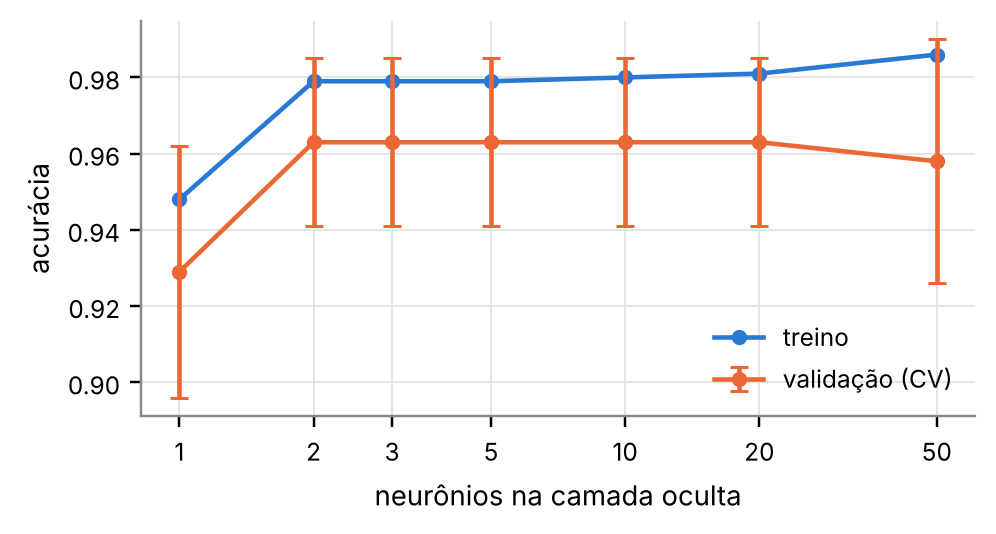

(98s)


In [29]:
t0 = time.time()
Hs = [1, 2, 3, 5, 10, 20, 50]
hid_res = []
for H in Hs:
    cv = cv_acc({**BASE, 'HiddenLayer': H, 'Epocas': 300, 'LearningRate': 0.1}, repeats=2)
    hid_res.append({'neurônios': H, 'acc treino': round(cv['treino'], 3), 'acc CV (média)': round(cv['media'], 3), 'acc CV (desvio)': round(cv['desvio'], 3)})
df_hid = pd.DataFrame(hid_res); display(df_hid)
fig, ax = plt.subplots(figsize=(4.6, 2.5))
ax.plot(Hs, df_hid['acc treino'], 'o-', color=C[0], ms=4, label='treino')
ax.errorbar(Hs, df_hid['acc CV (média)'], yerr=df_hid['acc CV (desvio)'], fmt='o-', color=C[1], ms=4, capsize=3, label='validação (CV)')
ax.set_xscale('log'); ax.set_xticks(Hs, [str(x) for x in Hs]); ax.minorticks_off()
ax.set_xlabel('neurônios na camada oculta'); ax.set_ylabel('acurácia'); ax.legend(loc='lower right')
fig.tight_layout(); salvar(fig, 'neuronios_ocultos'); plt.show()
R['ocultos'] = df_hid.to_dict('records'); print(f"({time.time()-t0:.0f}s)")

### Experimento 7 — Função de custo: MSE + sigmoide × entropia cruzada + *softmax*

Mesma rede (5 ocultos, sigmoide), lr = 0,1, z-score, 3 sementes. Para comparar na mesma escala, as curvas mostram o MSE das probabilidades de saída nos dois casos.

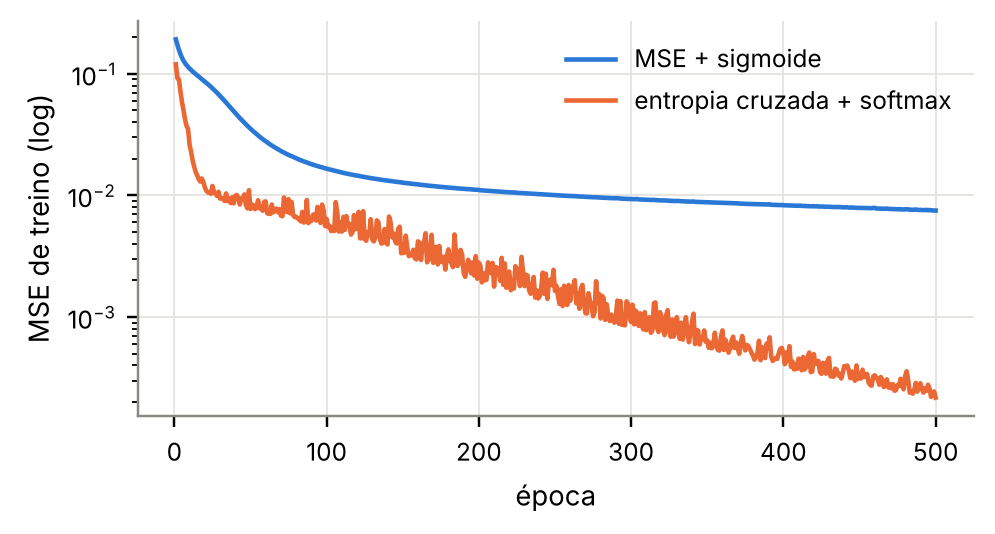

,custo,época p/ 95% (média),épocas por semente,MSE treino final,acc validação,acc CV (média),acc CV (desvio)
0,mse,37.666667,"[32, 53, 28]",0.0078,0.967,0.958,0.026
1,ce,7.333333,"[7, 11, 4]",0.0005,0.933,0.950,0.017


(28s)


In [30]:
t0 = time.time()
fig, ax = plt.subplots(figsize=(4.6, 2.5))
ce_res = []
for i, loss in enumerate(['mse', 'ce']):
    ep, accv, msef = [], [], []
    for s in range(3):
        m = MLP({**BASE, 'Loss': loss, 'Epocas': 500, 'LearningRate': 0.1, 'Seed': s}).fit(Xa_z, ya, Xv_z, yv)
        if s == 0:
            ax.plot(m.history_['epoch'], m.history_['train_mse'], color=C[i], label='MSE + sigmoide' if loss == 'mse' else 'entropia cruzada + softmax')
        ep.append(epoca_ate(m.history_)); accv.append(m.history_['val_acc'][-1]); msef.append(m.history_['train_mse'][-1])
    cv = cv_acc({**BASE, 'Loss': loss, 'Epocas': 300, 'LearningRate': 0.1})
    ce_res.append({'custo': loss, 'época p/ 95% (média)': float(np.nanmean(ep)), 'épocas por semente': ep,
                   'MSE treino final': round(float(np.mean(msef)), 4), 'acc validação': round(float(np.mean(accv)), 3),
                   'acc CV (média)': round(cv['media'], 3), 'acc CV (desvio)': round(cv['desvio'], 3)})
ax.set_yscale('log'); ax.set_xlabel('época'); ax.set_ylabel('MSE de treino (log)'); ax.legend()
fig.tight_layout(); salvar(fig, 'custo'); plt.show()
df_ce = pd.DataFrame(ce_res); display(df_ce)
R['custo'] = df_ce.to_dict('records'); print(f"({time.time()-t0:.0f}s)")

### Experimento 8 — *Overfitting*

A Iris tem pouco ruído, e com 120 amostras o *overfitting* é discreto. Para torná-lo visível, treinamos com **apenas 10 amostras por classe** (30 no total) e usamos as outras 90 amostras de treino como validação. Comparamos uma rede grande (50 ocultos, lr = 0,5) com a rede pequena (5 ocultos, lr = 0,1), por 3000 épocas, em 3 subconjuntos diferentes. Por fim, aplicamos *early stopping* (paciência de 200 épocas, restaurando os melhores pesos) e avaliamos no conjunto de teste.

,subconjunto,ocultos,lr,acc treino final,MSE treino final,época do menor MSE val.,MSE val. mínimo,MSE val. final,acc val. no mínimo,acc val. final,acc teste (3000 épocas),época early stopping,acc teste (early stopping)
0,0,50,0.5,1.0000,0.0001,225,0.0221,0.0480,0.9444,0.9111,1.0,225,1.0000
1,0,5,0.1,0.9667,0.0140,1739,0.0154,0.0158,0.9667,0.9667,1.0,1739,1.0000
2,1,50,0.5,1.0000,0.0000,32,0.0315,0.0369,0.9333,0.9333,1.0,32,1.0000
3,1,5,0.1,1.0000,0.0004,329,0.0328,0.0369,0.9556,0.9444,1.0,329,1.0000
4,2,50,0.5,1.0000,0.0000,40,0.0488,0.0754,0.8889,0.8778,0.9,40,0.9667
5,2,5,0.1,1.0000,0.0004,289,0.0496,0.0724,0.8889,0.8889,0.9,289,0.9667


,lr,acc treino final,MSE treino final,época do menor MSE val.,MSE val. mínimo,MSE val. final,acc val. no mínimo,acc val. final,acc teste (3000 épocas),época early stopping,acc teste (early stopping)
ocultos,,,,,,,,,,,
5,0.1,0.9889,0.0049,785.6667,0.0326,0.0417,0.9370,0.9333,0.9667,785.6667,0.9889
50,0.5,1.0000,0.0001,99.0000,0.0342,0.0534,0.9222,0.9074,0.9667,99.0000,0.9889


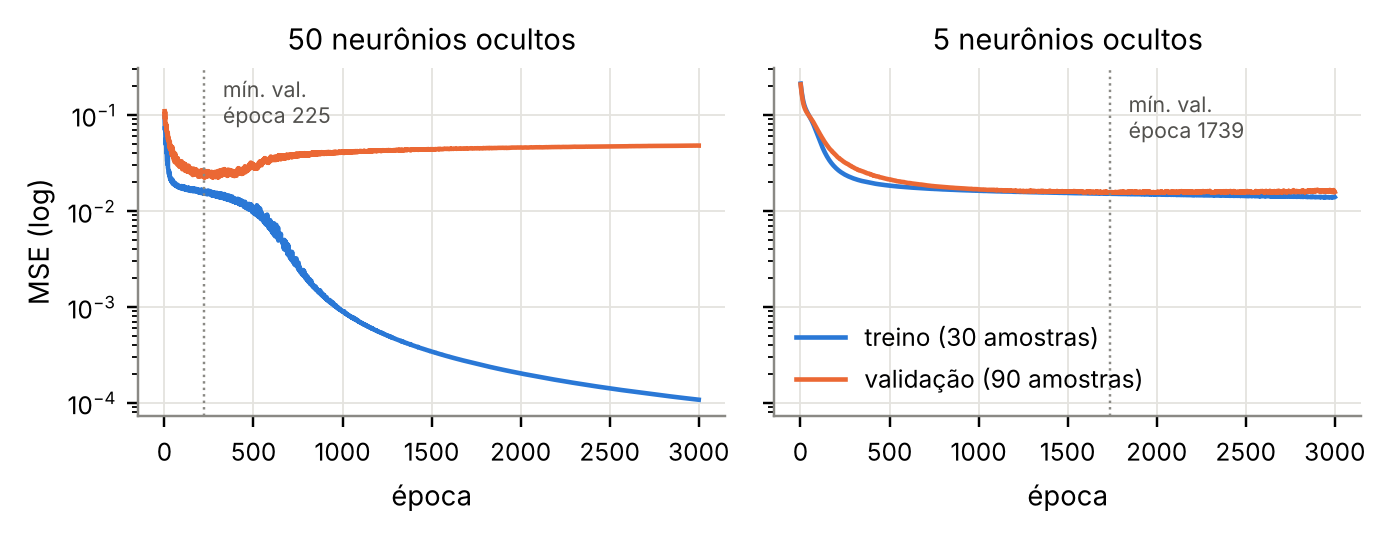

(41s)


In [31]:
t0 = time.time()
of_res, curvas = [], {}
for sub in range(3):
    rng = np.random.default_rng(sub)
    idx = np.concatenate([rng.choice(np.where(ytr == c)[0], 10, replace=False) for c in range(3)])
    resto = np.setdiff1d(np.arange(len(ytr)), idx)
    s = StandardScaler().fit(Xtr[idx])
    A, V, Te = s.transform(Xtr[idx]), s.transform(Xtr[resto]), s.transform(Xte)
    for H, lr in [(50, 0.5), (5, 0.1)]:
        p = {**BASE, 'HiddenLayer': H, 'LearningRate': lr, 'Epocas': 3000, 'Seed': sub}
        m = MLP(p).fit(A, ytr[idx], V, ytr[resto])
        hh = m.history_; vl = np.array(hh['val_loss']); b = int(vl.argmin())
        me = MLP(p).fit(A, ytr[idx], V, ytr[resto], early_stopping=200)
        of_res.append({'subconjunto': sub, 'ocultos': H, 'lr': lr,
                       'acc treino final': hh['train_acc'][-1], 'MSE treino final': hh['train_loss'][-1],
                       'época do menor MSE val.': b + 1, 'MSE val. mínimo': vl[b], 'MSE val. final': vl[-1],
                       'acc val. no mínimo': hh['val_acc'][b], 'acc val. final': hh['val_acc'][-1],
                       'acc teste (3000 épocas)': np.mean(m.predict(Te) == yte),
                       'época early stopping': me.best_epoch_, 'acc teste (early stopping)': np.mean(me.predict(Te) == yte)})
        if sub == 0:
            curvas[H] = hh
df_of = pd.DataFrame(of_res)
display(df_of.round(4))
resumo_of = df_of.groupby('ocultos').mean(numeric_only=True).drop(columns=['subconjunto'])
display(resumo_of.round(4))
R['overfitting'] = {'por_execucao': df_of.round(5).to_dict('records'), 'media': {int(k): v for k, v in resumo_of.round(5).to_dict('index').items()}}

fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.5), sharey=True)
for ax, H in zip(axs, [50, 5]):
    hh = curvas[H]; vl = np.array(hh['val_loss']); b = int(vl.argmin())
    ax.plot(hh['epoch'], hh['train_loss'], color=C[0], label='treino (30 amostras)')
    ax.plot(hh['epoch'], hh['val_loss'], color=C[1], label='validação (90 amostras)')
    ax.axvline(b + 1, color=GRAY, lw=0.8, ls=':')
    ax.annotate(f'mín. val.\népoca {b+1}', (b + 1, vl[b]), xytext=(6, 18), textcoords='offset points', fontsize=7, color='#52514e')
    ax.set_yscale('log'); ax.set_xlabel('época'); ax.set_title(f'{H} neurônios ocultos')
axs[0].set_ylabel('MSE (log)'); axs[1].legend(loc='lower left')
fig.tight_layout(); salvar(fig, 'overfitting'); plt.show()
print(f"({time.time()-t0:.0f}s)")

### Experimento 9 — Modelo final: teste reservado e validação cruzada

Configuração escolhida a partir dos experimentos anteriores: **z-score, 4–5–3, sigmoide, MSE, lr = 0,1, 300 épocas**.
(a) Treino nas 120 amostras e avaliação no teste reservado (30 amostras).
(b) Estimativa mais estável: validação cruzada estratificada de 10 *folds* × 5 repetições nas 150 amostras, com a matriz de confusão agregada (750 previsões) e a contagem de quantas vezes cada amostra foi errada.

In [32]:
FINAL = {**BASE, 'HiddenLayer': 5, 'LearningRate': 0.1, 'Epocas': 300}
s = StandardScaler().fit(Xtr)
final_test = []
for seed in range(5):
    mf = MLP({**FINAL, 'Seed': seed}).fit(s.transform(Xtr), ytr)
    final_test.append(float(np.mean(mf.predict(s.transform(Xte)) == yte)))
mf = MLP({**FINAL, 'Seed': 0}).fit(s.transform(Xtr), ytr)
pred_te = mf.predict(s.transform(Xte))
print("Acurácia de teste (5 sementes):", final_test)
print(classification_report(yte, pred_te, target_names=CLASS_NAMES, digits=3))
cm_te = confusion_matrix(yte, pred_te)
display(mf.predict_dataframe(s.transform(Xte), yte).head(10))
R['final_teste'] = {'acc_sementes': final_test, 'cm_semente0': cm_te.tolist()}

Acurácia de teste (5 sementes): [1.0, 1.0, 1.0, 1.0, 1.0]
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     1.000     1.000        10
   virginica      1.000     1.000     1.000        10

    accuracy                          1.000        30
   macro avg      1.000     1.000     1.000        30
weighted avg      1.000     1.000     1.000        30



,_id,class,output,hoped_output
0,0,Iris-versicolour,1,1
1,1,Iris-setosa,0,0
2,2,Iris-versicolour,1,1
3,3,Iris-virginica,2,2
4,4,Iris-virginica,2,2
5,5,Iris-versicolour,1,1
6,6,Iris-virginica,2,2
7,7,Iris-setosa,0,0
8,8,Iris-virginica,2,2
9,9,Iris-setosa,0,0


CV 10x5: acurácia = 0.9733 ± 0.0422  (97s)
Matriz de confusão agregada (linhas = real, colunas = previsto):
 [[250   0   0]
 [  0 235  15]
 [  0   5 245]]


,índice,classe real,vezes errada (de 5),pétala comp.,pétala larg.
1,70,versicolor,5,4.8,1.8
5,133,virginica,5,5.1,1.5
4,83,versicolor,5,5.1,1.6
3,77,versicolor,2,5.0,1.7
2,72,versicolor,2,4.9,1.5
0,68,versicolor,1,4.5,1.5


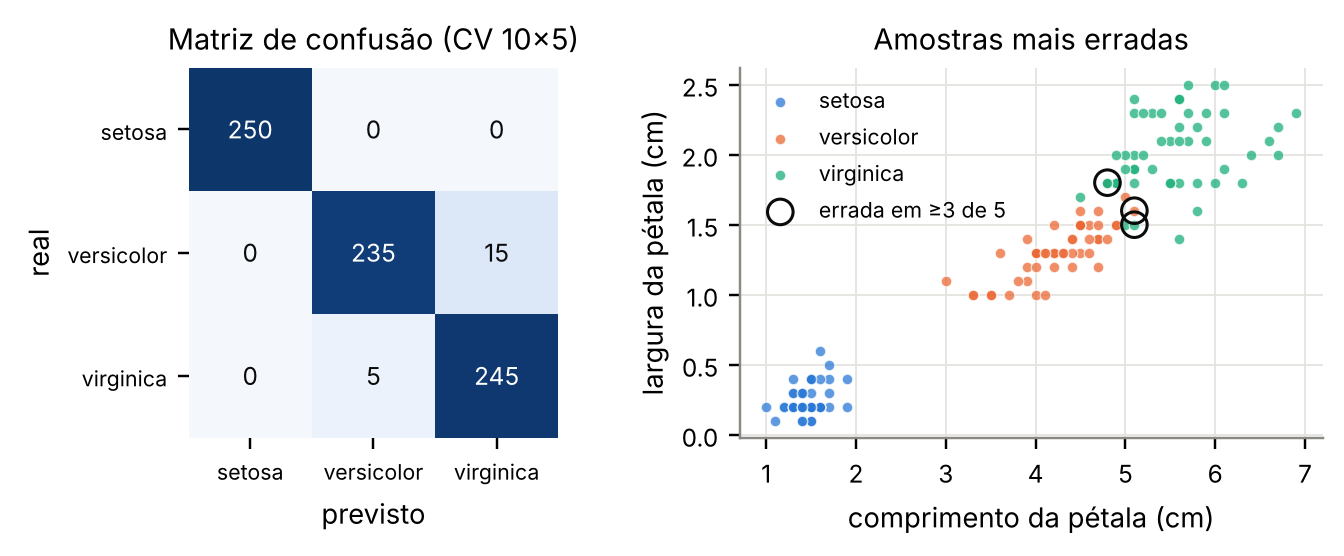

In [33]:
t0 = time.time()
rskf = RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=42)
accs, cm_tot, erros = [], np.zeros((3, 3), int), np.zeros(len(y_all), int)
for k, (a, v) in enumerate(rskf.split(X_all, y_all)):
    sk = StandardScaler().fit(X_all[a])
    m = MLP({**FINAL, 'Seed': k}).fit(sk.transform(X_all[a]), y_all[a])
    pv = m.predict(sk.transform(X_all[v]))
    accs.append(np.mean(pv == y_all[v])); cm_tot += confusion_matrix(y_all[v], pv, labels=[0, 1, 2])
    erros[v] += (pv != y_all[v])
print(f"CV 10x5: acurácia = {np.mean(accs):.4f} ± {np.std(accs):.4f}  ({time.time()-t0:.0f}s)")
print("Matriz de confusão agregada (linhas = real, colunas = previsto):\n", cm_tot)
dif = np.where(erros > 0)[0]
tab_err = pd.DataFrame({'índice': dif, 'classe real': [CLASS_NAMES[y_all[i]] for i in dif], 'vezes errada (de 5)': erros[dif],
                        'pétala comp.': X_all[dif, 2], 'pétala larg.': X_all[dif, 3]}).sort_values('vezes errada (de 5)', ascending=False)
display(tab_err)
R['cv_final'] = {'media': float(np.mean(accs)), 'desvio': float(np.std(accs)), 'cm': cm_tot.tolist(),
                 'erros': {int(i): int(erros[i]) for i in dif}}

fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.6), gridspec_kw={'width_ratios': [1, 1.25]})
ax = axs[0]
ax.imshow(cm_tot, cmap=mpl.colors.LinearSegmentedColormap.from_list('b', ['#f4f8fd', '#2a78d6', '#0d366b']))
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm_tot[i, j], ha='center', va='center', fontsize=8, color='white' if cm_tot[i, j] > cm_tot.max() / 2 else '#0b0b0b')
ax.set_xticks(range(3), CLASS_NAMES, fontsize=7); ax.set_yticks(range(3), CLASS_NAMES, fontsize=7)
ax.set_xlabel('previsto'); ax.set_ylabel('real'); ax.grid(False); ax.set_title('Matriz de confusão (CV 10×5)')
for sp in ax.spines.values(): sp.set_visible(False)
ax = axs[1]
for c in range(3):
    mk = y_all == c
    ax.scatter(X_all[mk, 2], X_all[mk, 3], s=12, color=C[c], alpha=0.75, label=CLASS_NAMES[c], edgecolors='white', linewidths=0.4)
mk = erros >= 3
ax.scatter(X_all[mk, 2], X_all[mk, 3], s=70, facecolors='none', edgecolors='#0b0b0b', linewidths=1.0, label='errada em ≥3 de 5')
ax.set_xlabel('comprimento da pétala (cm)'); ax.set_ylabel('largura da pétala (cm)'); ax.legend(loc='upper left', fontsize=7)
ax.set_title('Amostras mais erradas')
fig.tight_layout(); salvar(fig, 'erros_final'); plt.show()

### Experimento 10 — Fronteiras de decisão (2 atributos)

Para visualizar o que a rede aprende, treinamos com apenas **comprimento e largura da pétala** (z-score, 2000 épocas). Com 1 neurônio oculto, tudo passa por uma única projeção e as fronteiras são retas paralelas. Com 5 neurônios elas continuam quase retas, porque em 2D as classes são quase linearmente separáveis. No último painel, a rede de 50 neurônios foi treinada com só 10 amostras por classe e lr = 0,5, o regime de *overfitting* do Experimento 8: as fronteiras ficam irregulares e contornam as amostras de treino.

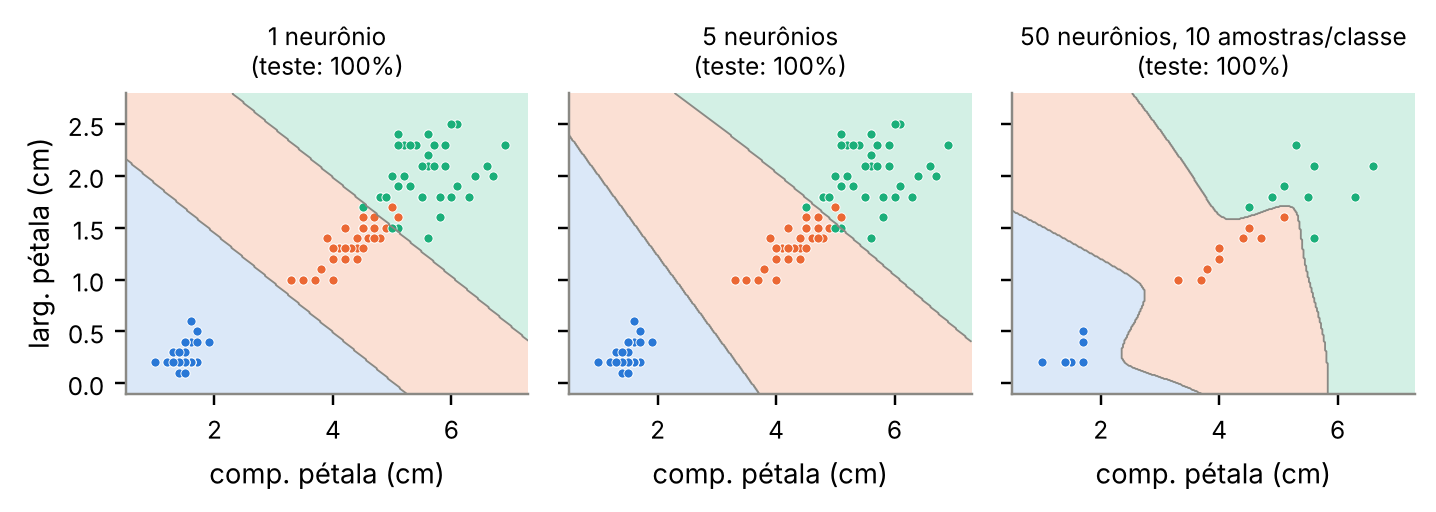

,config,acc treino,acc teste
0,1 neurônio,0.958333,1.0
1,5 neurônios,0.958333,1.0
2,"50 neurônios, 10 amostras/classe",1.000000,1.0


(28s)


In [34]:
t0 = time.time()
F = [2, 3]
s2 = StandardScaler().fit(Xtr[:, F])
rng = np.random.default_rng(0)
idx10 = np.concatenate([rng.choice(np.where(ytr == c)[0], 10, replace=False) for c in range(3)])
cfgs = [('1 neurônio', 1, 0.1, np.arange(len(ytr))), ('5 neurônios', 5, 0.1, np.arange(len(ytr))),
        ('50 neurônios, 10 amostras/classe', 50, 0.5, idx10)]
gx, gy = np.meshgrid(np.linspace(0.5, 7.3, 300), np.linspace(-0.1, 2.8, 300))
G = s2.transform(np.c_[gx.ravel(), gy.ravel()])
cmap_bg = mpl.colors.ListedColormap(['#dbe8f8', '#fbe0d4', '#d3f0e5'])
fig, axs = plt.subplots(1, 3, figsize=(6.6, 2.4), sharey=True)
fr = []
for ax, (tit, H, lr, ii) in zip(axs, cfgs):
    m = MLP({**BASE, 'InputLayer': 2, 'HiddenLayer': H, 'LearningRate': lr, 'Epocas': 2000, 'Seed': 0}).fit(s2.transform(Xtr[ii][:, F]), ytr[ii])
    Z = m.predict(G).reshape(gx.shape)
    ax.contourf(gx, gy, Z, levels=[-0.5, 0.5, 1.5, 2.5], cmap=cmap_bg)
    ax.contour(gx, gy, Z, levels=[0.5, 1.5], colors=GRAY, linewidths=0.6)
    for c in range(3):
        mk = ytr[ii] == c
        ax.scatter(Xtr[ii][mk, 2], Xtr[ii][mk, 3], s=9, color=C[c], edgecolors='white', linewidths=0.3)
    acc_t = np.mean(m.predict(s2.transform(Xte[:, F])) == yte)
    fr.append({'config': tit, 'acc treino': float(np.mean(m.predict(s2.transform(Xtr[ii][:, F])) == ytr[ii])), 'acc teste': float(acc_t)})
    ax.set_title(f'{tit}\n(teste: {acc_t:.0%})', fontsize=8); ax.set_xlabel('comp. pétala (cm)'); ax.grid(False)
axs[0].set_ylabel('larg. pétala (cm)')
fig.tight_layout(); salvar(fig, 'fronteiras'); plt.show()
display(pd.DataFrame(fr)); R['fronteiras'] = fr; print(f"({time.time()-t0:.0f}s)")

### Experimento 11 — Comparação com o `MLPClassifier` do scikit-learn

Verificação de sanidade: mesma arquitetura (5 neurônios logísticos), mesmo protocolo de CV 10×5 nas 150 amostras.

In [35]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score
from sklearn.exceptions import ConvergenceWarning
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    sk = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(5,), activation='logistic', solver='adam',
                                                       learning_rate_init=0.01, max_iter=2000, random_state=0))
    sc_sk = cross_val_score(sk, X_all, y_all, cv=RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=42))
print(f"sklearn MLPClassifier: {sc_sk.mean():.4f} ± {sc_sk.std():.4f}")
print(f"MLP from scratch     : {R['cv_final']['media']:.4f} ± {R['cv_final']['desvio']:.4f}")
R['sklearn'] = {'media': float(sc_sk.mean()), 'desvio': float(sc_sk.std())}

sklearn MLPClassifier: 0.9693 ± 0.0446
MLP from scratch     : 0.9733 ± 0.0422


In [36]:
def _conv(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
json.dump(R, open('resultados.json', 'w'), indent=1, default=_conv, ensure_ascii=False)
print("resultados.json salvo;", len(os.listdir(FIG_DIR)), "arquivos em", FIG_DIR)

resultados.json salvo; 18 arquivos em figuras


---
## Conclusões

* **Por que a virginica não era classificada:** o problema estava nos dados, não na rede. O `random.shuffle` em array NumPy deixou só 6 virginica entre 150 amostras (74 distintas), e o teste ficou com uma única virginica.
* Mais dois bugs críticos tornavam o resultado do notebook não confiável: o `predict` sem ativação, que avalia outra função, e os bias inteiros, que nunca são aprendidos.
* **Com as correções**, a rede 4–5–3 classifica bem as três classes: acerta 100% do teste reservado (5 sementes) e 97,3% ± 4,2% na CV 10×5, desempenho equivalente ao do `MLPClassifier` do scikit-learn. Os erros restantes estão todos na fronteira **versicolor × virginica**, que não é linearmente separável, e se concentram em 3 flores.
* **Convergência:** a configuração original converge devagar, com um platô inicial longo (cerca de 570 épocas até 95% de acerto no treino). O fator decisivo é a taxa de aprendizado: com lr = 0,1 bastam cerca de 38 épocas, e com lr = 1, cerca de 5. Com lr = 50 os neurônios saturam e o treino trava. A padronização deixa a convergência mais suave, mas o ganho é pequeno, porque os atributos da Iris já estão em escalas parecidas. Entropia cruzada com softmax converge cerca de 5× mais rápido que MSE com sigmoide.
* **Overfitting:** é discreto na Iris com 120 amostras. Com poucas amostras e muitos neurônios, o erro de treino vai a ~0 enquanto o de validação passa por um mínimo e volta a subir. O *early stopping* evita isso. Poucos neurônios (2–10) já bastam.

Os valores exatos estão nas tabelas acima e em `resultados.json`.